# Understanding the DKD experiment, end to end

This notebook is the map of the project as it stands through Colab training.
It does not launch the 240-epoch run. Training stays in `scripts/train.py` and
`notebooks/03_colab_training_and_logging.ipynb`. Everything below reuses the
code in `src/` and, where a checkpoint already exists, the weights on disk.

The paper is Zhao, Cui, Song, Qiu, and Liang, *Decoupled Knowledge Distillation*,
CVPR 2022, pp. 11953–11962. The recipe we copy is the CIFAR-100 pair
**ResNet32×4 teacher → ResNet8×4 student**. The number we are trying to land
near is **76.32%** top-1 for the student, with about a 1 point tolerance
because the paper reports a five-trial average.

Read it from the top. Later cells reuse tensors computed earlier.

What you can take out of a run:

1. Why train and test CIFAR-100 look the way they do, and what is actually different about a training view.
2. The teacher and student graphs, side by side, including a traced torchview diagram and the tensor shape at each stage.
3. The only place the two networks meet: the 100 logits.
4. The exact split of classical KD into TCKD and NCKD, checked on the paper's 3-class numbers and on a real batch.
5. What α, β, T, warmup, and the learning-rate drops do to that loss.
6. Where backpropagation is allowed to go, and where it is cut.
7. How to talk about the whole thing in class without hand-waving.


## 0. Setup

The kernel's working directory may be the repo root or `notebooks/`.
The next cell finds the root, imports our package, and sets one plotting style.


In [23]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

%matplotlib inline

REPO = Path.cwd().resolve()
if not (REPO / "src").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

from src.data.cifar100 import (
    CIFAR100_MEAN,
    CIFAR100_STD,
    CIFAR100Dataset,
    load_cifar100,
    make_splits,
    preprocess_eval,
    preprocess_train,
)
from src.engine.trainer import adjust_learning_rate, build_optimizer, load_config
from src.losses.dkd import (
    DistillationLoss,
    dkd_loss,
    kd_loss,
    kd_loss_from_decoupled_terms,
    nckd_per_sample,
    tckd_per_sample,
    warmup_factor,
)
from src.models.resnet import load_pretrained_teacher, resnet8x4, resnet32x4

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "font.size": 11,
})

TEACHER_COLOR = "#1f4e79"
STUDENT_COLOR = "#c45911"
TCKD_COLOR = "#2e7d32"
NCKD_COLOR = "#6a1b9a"
CE_COLOR = "#455a64"
ACCENT = "#b45309"

print("repo:", REPO)
print("torch:", torch.__version__)


repo: /Users/sufyan.siddiqui/ML-Project
torch: 2.15.0


In [ ]:
# Download CIFAR-100 (about 161 MB) into data/ the first time this runs.
# Skipped when data/cifar-100-python already has train, test, and meta.
from scripts.setup_project import ensure_cifar100

ensure_cifar100()

## 1. The experiment on one page

A large network (the teacher) is already correct often enough to be worth copying.
A small network (the student) is what we actually want to ship. Classical knowledge
distillation trains the student on the hard label **and** on the teacher's soft
probability vector. That soft vector is the "dark knowledge": not only "this is a
maple tree", but "if it is not, it looks more like an oak than like a tractor".

DKD does not change the data, the architectures, or the hard-label term.
It only rewrites the soft term so two different kinds of agreement can be
weighted separately.

| Piece | Our choice | Where it lives |
| --- | --- | --- |
| Data | CIFAR-100, 32×32 RGB, 100 fine classes | `src/data/cifar100.py` |
| Teacher | ResNet32×4, pretrained with plain cross-entropy, then frozen | `src/models/resnet.py` |
| Student | ResNet8×4, trained from scratch | same file |
| Loss modes | `ce`, `kd`, `dkd`, `tckd_only`, `nckd_only` | `src/losses/dkd.py` |
| Optimiser | SGD, lr 0.05, momentum 0.9, weight decay 5e-4, 240 epochs | `configs/cifar100_resnet32x4_resnet8x4.yaml` |
| LR drops | ×0.1 at epochs 150, 180, 210 | same file |
| DKD knobs | α=1, β=8, T=4, linear warmup over 20 epochs | same file |

Five students, identical except for the loss, are the whole comparison:

- **CE** — hard labels only. The baseline that never sees the teacher.
- **KD** — hard labels plus classical KL between teacher and student probabilities.
- **TCKD only** — α=1, β=0. Binary "true class versus everything else".
- **NCKD only** — α=0, β=8. The ranking among the other 99 classes.
- **DKD** — α=1, β=8. Both, with independent weights.

The config cell below prints the file we actually train with, so the table cannot drift from the code.


In [24]:
cfg = load_config(REPO / "configs" / "cifar100_resnet32x4_resnet8x4.yaml")
print("dataset: ", cfg["dataset"])
print("teacher: ", cfg["teacher"])
print("student: ", cfg["student"])
print("solver:  ", cfg["solver"])
print("dkd:     ", cfg["dkd"])
print("mean/std:", cfg["preprocess"]["mean"], cfg["preprocess"]["std"])


dataset:  cifar100
teacher:  resnet32x4
student:  resnet8x4
solver:   {'optimizer': 'SGD', 'epochs': 240, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.0005, 'lr_decay_stages': [150, 180, 210], 'lr_decay_rate': 0.1}
dkd:      {'ce_weight': 1.0, 'alpha': 1.0, 'beta': 8.0, 'temperature': 4.0, 'warmup_epochs': 20}
mean/std: [0.5071, 0.4867, 0.4408] [0.2675, 0.2565, 0.2761]


## 2. The identity the paper is built on

Take one image whose true class is `t`. After a softmax, the 100 probabilities
contain two decisions stacked on top of each other:

1. **Target versus the rest.** How much mass sits on the true class, `p_t`, versus on all other classes together, `p_{\t} = 1 - p_t`. Call this binary vector `b = [p_t, p_{\t}]`.
2. **Which of the others.** If the mass is not on `t`, how is it shared among the remaining classes? That is a softmax computed only on the non-target logits. Call it `p̂`.

Those two pieces multiply back to the original probabilities. For every class `i` other than `t`:

```text
p_i = p̂_i * p_{\t}
```

Substitute that bridge into `KL(p_teacher || p_student)` and the KL splits with no approximation:

```text
KD = KL(b_teacher || b_student) + (1 - p_t_teacher) * KL(p̂_teacher || p̂_student)
   = TCKD                       + (1 - p_t_teacher) * NCKD
```

**TCKD** (target-class KD) only says whether the teacher and the student agree on how confident the true class should be. That is sample-difficulty information.

**NCKD** (non-target-class KD) is the dark knowledge: the ordering of the wrong classes.

The coupling problem is the multiplier `(1 - p_t_teacher)`. When the teacher is sure, that multiplier is near zero, so the dark knowledge is almost deleted from the loss. A single global KD weight cannot fix this, because the suppression is different for every sample. TCKD and NCKD also do different jobs, so they should not be forced to share one coefficient.

DKD replaces the sample-wise multiplier with a constant β, and gives TCKD its own constant α:

```text
L_DKD = (α * TCKD + β * NCKD) * T^2
L_total = cross_entropy(student, label) + warmup * L_DKD
```

`T^2` is the usual temperature rescaling from Hinton's KD. Our training temperature is 4, so this factor is 16. Dropping it would silently change the learning rate on the distillation term.

The next cell recomputes the paper's 3-class check with **our** functions, at T=1, which is the temperature used in that worked example. The classes are cat (the label), dog, and car. Teacher logits `[4, 1, 0]`, student logits `[3, 1.5, 0]`.


teacher probabilities:  [0.9362 0.0466 0.0171]   non-target mass 0.0638
student probabilities:  [0.7856 0.1753 0.0391]   non-target mass 0.2144
teacher non-target conditional p-hat: [0.7311 0.2689]
student non-target conditional p-hat: [0.8176 0.1824]
bridge check, dog: p = p-hat * p_not -> 0.0466 vs 0.0466

TCKD                         0.086918
NCKD                         0.022622
(1 - p_t) * NCKD             0.001442   <- what classical KD actually uses
TCKD + (1 - p_t) * NCKD      0.088361
classical KL                 0.088361
same KL via our split        0.088361
absolute gap                 2.776e-17


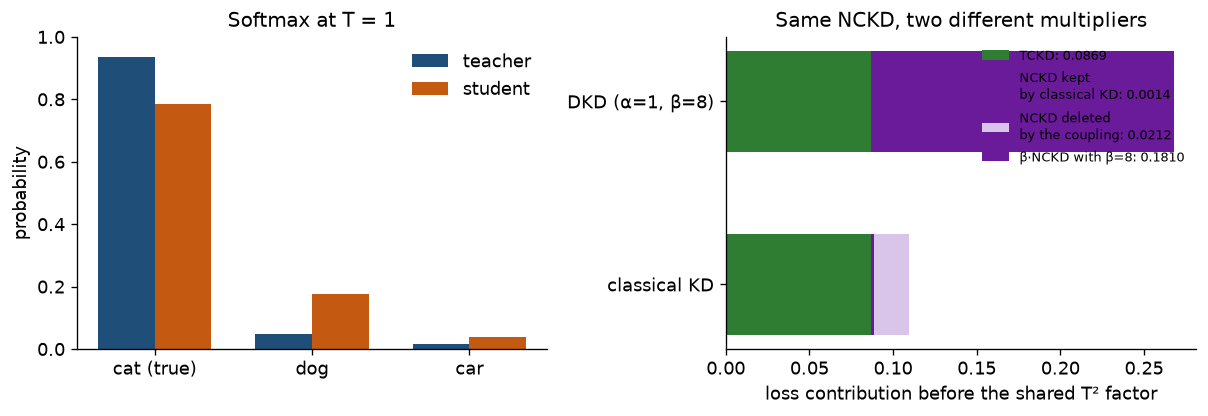

On this example the teacher puts 93.6% on cat, so classical KD keeps 6.4% of NCKD. DKD with β=8 keeps all of it, then multiplies by 8.


In [25]:
logits_t = torch.tensor([[4.0, 1.0, 0.0]], dtype=torch.float64)
logits_s = torch.tensor([[3.0, 1.5, 0.0]], dtype=torch.float64)
target = torch.tensor([0])
names = ["cat (true)", "dog", "car"]

def softmax_row(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

pt = softmax_row(logits_t.numpy()[0])
ps = softmax_row(logits_s.numpy()[0])
# Bridge: non-target probabilities, renormalised so they sum to 1.
phat_t = pt[1:] / pt[1:].sum()
phat_s = ps[1:] / ps[1:].sum()

print("teacher probabilities: ", np.round(pt, 4), "  non-target mass", round(1 - pt[0], 4))
print("student probabilities: ", np.round(ps, 4), "  non-target mass", round(1 - ps[0], 4))
print("teacher non-target conditional p-hat:", np.round(phat_t, 4))
print("student non-target conditional p-hat:", np.round(phat_s, 4))
print("bridge check, dog: p = p-hat * p_not ->", round(phat_t[0] * (1 - pt[0]), 4), "vs", round(pt[1], 4))

tckd = tckd_per_sample(logits_s, logits_t, target, temperature=1.0).item()
nckd = nckd_per_sample(logits_s, logits_t, target, temperature=1.0).item()
kd_direct = kd_loss(logits_s, logits_t, temperature=1.0).item()
kd_split = kd_loss_from_decoupled_terms(logits_s, logits_t, target, temperature=1.0).item()
coupled_nckd = (1 - pt[0]) * nckd

print()
print(f"TCKD                         {tckd:.6f}")
print(f"NCKD                         {nckd:.6f}")
print(f"(1 - p_t) * NCKD             {coupled_nckd:.6f}   <- what classical KD actually uses")
print(f"TCKD + (1 - p_t) * NCKD      {tckd + coupled_nckd:.6f}")
print(f"classical KL                 {kd_direct:.6f}")
print(f"same KL via our split        {kd_split:.6f}")
print(f"absolute gap                 {abs(kd_direct - kd_split):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6))

x = np.arange(3)
axes[0].bar(x - 0.18, pt, width=0.36, color=TEACHER_COLOR, label="teacher")
axes[0].bar(x + 0.18, ps, width=0.36, color=STUDENT_COLOR, label="student")
axes[0].set_xticks(x, names)
axes[0].set_ylabel("probability")
axes[0].set_title("Softmax at T = 1")
axes[0].legend(frameon=False)
axes[0].set_ylim(0, 1)

parts = {
    "TCKD": tckd,
    "NCKD kept\nby classical KD": coupled_nckd,
    "NCKD deleted\nby the coupling": nckd - coupled_nckd,
}
colors = [TCKD_COLOR, NCKD_COLOR, "#d9c4ea"]
left = 0.0
for (label, value), color in zip(parts.items(), colors):
    axes[1].barh(0, value, left=left, color=color, height=0.55, label=f"{label}: {value:.4f}")
    left += value
axes[1].barh(1, tckd, color=TCKD_COLOR, height=0.55)
axes[1].barh(1, 8 * nckd, left=tckd, color=NCKD_COLOR, height=0.55, label=f"β·NCKD with β=8: {8 * nckd:.4f}")
axes[1].set_yticks([0, 1], ["classical KD", "DKD (α=1, β=8)"])
axes[1].set_xlabel("loss contribution before the shared T² factor")
axes[1].set_title("Same NCKD, two different multipliers")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

print(
    "On this example the teacher puts 93.6% on cat, so classical KD keeps "
    f"{coupled_nckd / nckd:.1%} of NCKD. DKD with β=8 keeps all of it, then multiplies by 8."
)


### What the two terms are teaching

TCKD is useful when the training signal is hard: strong augmentation, noisy labels, ImageNet.
On plain CIFAR-100 the images are easy to memorise, and the paper finds TCKD alone can fail to help.
NCKD is the term that carries the gain. The awkward part of the classical formula is that it
turns NCKD **down** on the samples where the teacher is most trustworthy, which is exactly
where that ranking of wrong classes is most reliable.

The figure above is the whole paper in one picture. The rest of this notebook is that
picture attached to our data, our two ResNets, and our training loop.

Temperature was 1 in the worked example so the probabilities stay sharp enough to see.
Training uses T=4. A later section puts that temperature back in.


## 3. CIFAR-100, before any network touches it

CIFAR-100 (Krizhevsky, 2009) is 50,000 training images and 10,000 test images.
Each image is 32×32 RGB. Each image has a **fine** label (100 classes, 500 train
and 100 test each) and a **coarse** label (20 superclasses, 5 fine classes each).

We train and evaluate on the fine labels. The coarse labels are still worth
looking at, because dark knowledge usually falls inside a superclass: a willow
is closer to a maple than to a rocket. The distillation loss is free to learn
that; the one-hot label is not.

The loader in `src/data/cifar100.py` reads the official Python batches.
Pixels stay uint8 until a later preprocessing step, so the histograms in this
section are the raw data, not the normalised tensors the network sees.


train images: 50000   shape (32, 32, 3)   dtype uint8
test images:  10000
fine classes: 100   balanced train/test: True / True
per fine class, train min/max: 500 / 500
per fine class, test  min/max: 100 / 100
coarse classes: 20
example superclass -> fine classes:
  aquatic_mammals: ['otter', 'seal', 'whale', 'beaver', 'dolphin']
  fish: ['aquarium_fish', 'shark', 'flatfish', 'ray', 'trout']
  flowers: ['sunflower', 'rose', 'tulip', 'poppy', 'orchid']


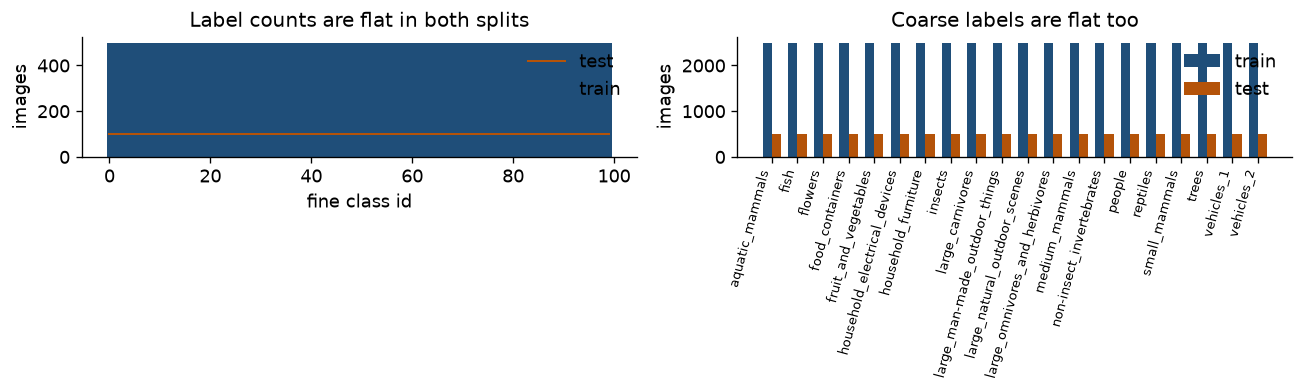

In [26]:
data = load_cifar100(REPO / "data" / "cifar-100-python")
splits = make_splits(data)
fine_names = data["fine_names"]
coarse_names = data["coarse_names"]

print(f"train images: {splits['n_train']}   shape {splits['image_shape']}   dtype {data['train_images'].dtype}")
print(f"test images:  {splits['n_test']}")
print(f"fine classes: {splits['n_fine']}   balanced train/test: {splits['train_balanced']} / {splits['test_balanced']}")
print(f"per fine class, train min/max: {splits['train_fine_counts'].min()} / {splits['train_fine_counts'].max()}")
print(f"per fine class, test  min/max: {splits['test_fine_counts'].min()} / {splits['test_fine_counts'].max()}")
print(f"coarse classes: {splits['n_coarse']}")
print("example superclass -> fine classes:")
for coarse_id in range(3):
    members = [fine_names[i] for i in splits["fine_per_coarse"][coarse_id]]
    print(f"  {coarse_names[coarse_id]}: {members}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(np.arange(100), splits["train_fine_counts"], color=TEACHER_COLOR, width=1.0, label="train")
axes[0].plot(np.arange(100), splits["test_fine_counts"], color=ACCENT, lw=1.2, label="test")
axes[0].set_xlabel("fine class id")
axes[0].set_ylabel("images")
axes[0].set_title("Label counts are flat in both splits")
axes[0].legend(frameon=False)
axes[1].bar(np.arange(20) - 0.18, splits["train_coarse_counts"], width=0.36, color=TEACHER_COLOR, label="train")
axes[1].bar(np.arange(20) + 0.18, splits["test_coarse_counts"], width=0.36, color=ACCENT, label="test")
axes[1].set_xticks(np.arange(20), coarse_names, rotation=75, ha="right", fontsize=8)
axes[1].set_ylabel("images")
axes[1].set_title("Coarse labels are flat too")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()


The label distribution does not need to be "fit". Every class is equally common,
in train and in test. A model that ignored the images and always predicted one
class would score 1% top-1. There is also no train/test class shift to blame
if the student underperforms.

What *can* differ is the pixel distribution, and the random training views.
The next cells separate those two.


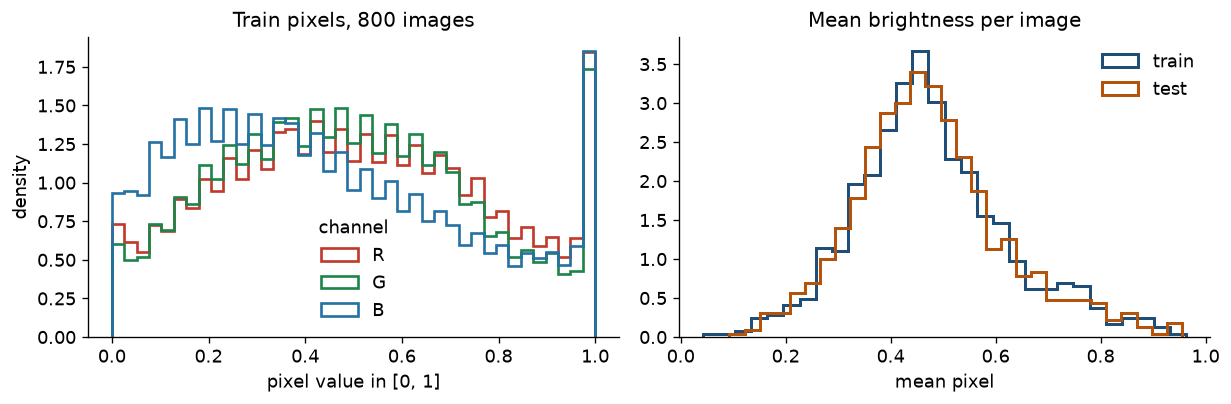

channel means train [0.503 0.489 0.44 ]  test [0.503 0.482 0.44 ]
The recipe does not estimate these. It uses the fixed constants [0.507099986076355, 0.48669999837875366, 0.4408000111579895] and [0.26750001311302185, 0.2565000057220459, 0.2761000096797943]


In [27]:
rng = np.random.default_rng(0)

def sample_pixels(images, n_images, generator):
    idx = generator.choice(len(images), size=n_images, replace=False)
    return images[idx].astype(np.float32) / 255.0

train_pix = sample_pixels(data["train_images"], 800, rng)
test_pix = sample_pixels(data["test_images"], 800, rng)
bins = np.linspace(0, 1, 40)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.5))
channel_colors = ["#c0392b", "#1e8449", "#2471a3"]
for c, color in enumerate(channel_colors):
    axes[0].hist(train_pix[..., c].ravel(), bins=bins, histtype="step", density=True, color=color, lw=1.6, label="RGB"[c])
axes[0].set_title("Train pixels, 800 images")
axes[0].set_xlabel("pixel value in [0, 1]")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, title="channel")

for c, color in enumerate(channel_colors):
    axes[1].hist(
        train_pix.mean(axis=(1, 2, 3)),
        bins=30,
        density=True,
        histtype="step",
        lw=1.8,
        color=TEACHER_COLOR,
        label="train" if c == 0 else None,
    )
    axes[1].hist(
        test_pix.mean(axis=(1, 2, 3)),
        bins=30,
        density=True,
        histtype="step",
        lw=1.8,
        color=ACCENT,
        label="test" if c == 0 else None,
    )
axes[1].set_title("Mean brightness per image")
axes[1].set_xlabel("mean pixel")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

print(
    "channel means train",
    np.round(train_pix.mean(axis=(0, 1, 2)), 3),
    " test",
    np.round(test_pix.mean(axis=(0, 1, 2)), 3),
)
print(
    "The recipe does not estimate these. It uses the fixed constants",
    CIFAR100_MEAN.tolist(),
    "and",
    CIFAR100_STD.tolist(),
)


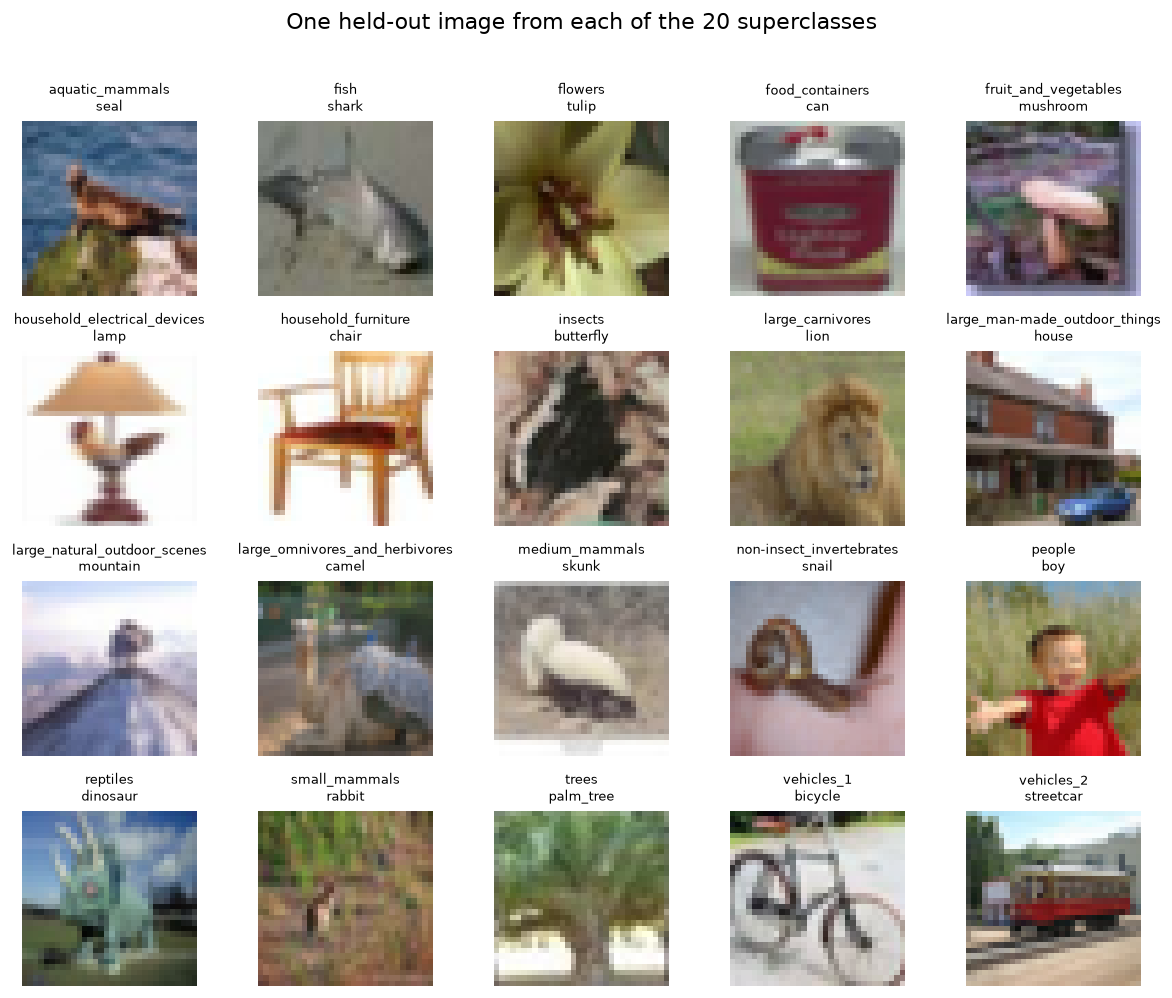

In [28]:
# One photo from each superclass, taken from the test split so we do not stare at training images only.
fig, axes = plt.subplots(4, 5, figsize=(10, 8.2))
shown = set()
for coarse_id in range(20):
    ax = axes[coarse_id // 5, coarse_id % 5]
    hits = np.flatnonzero(data["test_coarse"] == coarse_id)
    image_id = int(hits[0])
    fine_id = int(data["test_fine"][image_id])
    ax.imshow(data["test_images"][image_id])
    ax.set_title(f"{coarse_names[coarse_id]}\n{fine_names[fine_id]}", fontsize=8)
    ax.axis("off")
    shown.add(fine_id)
fig.suptitle("One held-out image from each of the 20 superclasses", y=1.01)
fig.tight_layout()
plt.show()


## 4. The distribution the network actually fits

`preprocess_train` and `preprocess_eval` are the two views in the recipe.

A **test** view is only: divide by 255, subtract the fixed mean, divide by the fixed std, and transpose to channel-first. No crop, no flip.

A **train** view, before that normalisation, does two random things:

- pad 4 zero pixels on each side (the border is black, matching torchvision's fill), then crop a 32×32 window;
- flip left-right with probability 1/2.

So the train and test *datasets* come from the same balanced distribution, but each training step shows a jittered copy. The student has to treat those copies as the same class. The test score is measured on the clean, centred images. That gap, not a shift in class frequencies, is the generalisation gap this recipe cares about.

Normalised tensors are a poor thing to look at directly (values are roughly between −2 and 2, and the channels are rescaled differently). The grid below shows the training views **before** normalisation, which is the geometric part. The histogram then shows the tensors the convolution actually receives.


demo image 32 label maple_tree


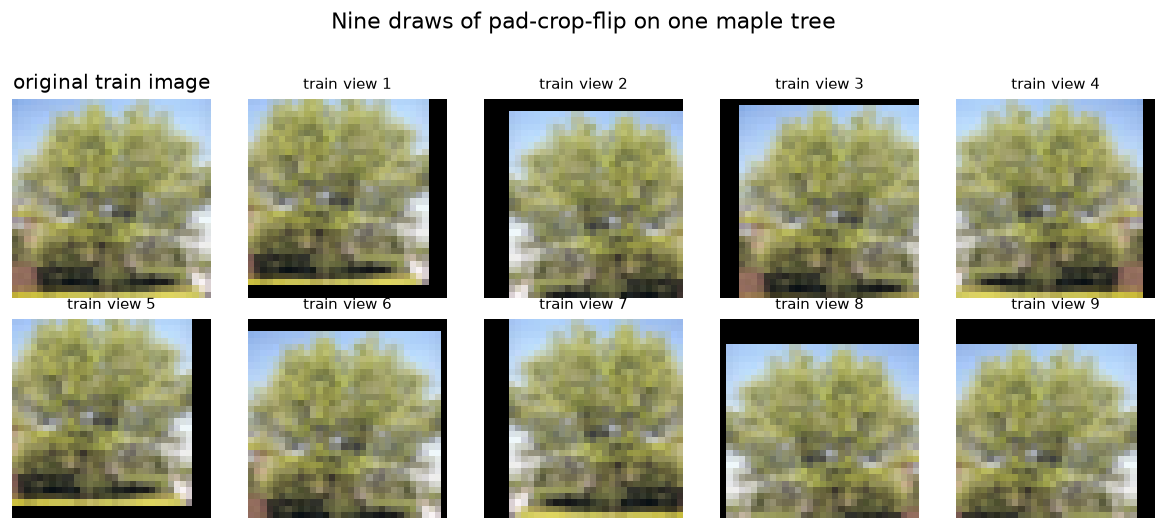

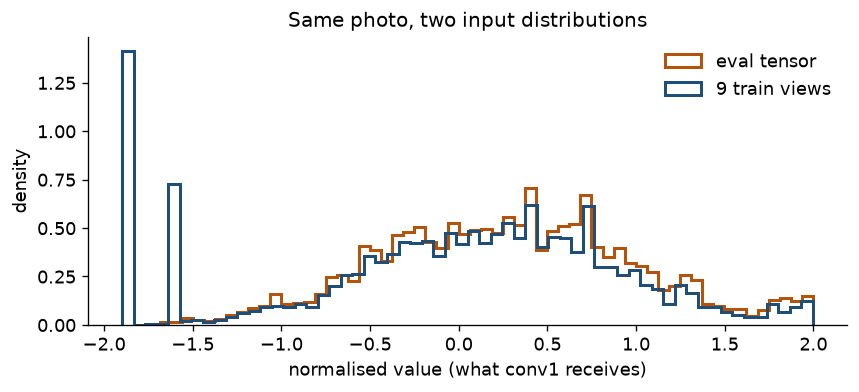

In [29]:
demo_id = int(np.flatnonzero(data["train_fine"] == fine_names.index("maple_tree"))[0])
demo = data["train_images"][demo_id]
print("demo image", demo_id, "label", fine_names[int(data["train_fine"][demo_id])])

fig, axes = plt.subplots(2, 5, figsize=(10, 4.3))
axes[0, 0].imshow(demo)
axes[0, 0].set_title("original train image")
axes[0, 0].axis("off")
views = []
for k in range(9):
    view_rng = np.random.default_rng(100 + k)
    chw = preprocess_train(demo, rng=view_rng)
    views.append(chw)
    # Undo the crop/flip only for display: denormalise the tensor back to RGB.
    rgb = np.transpose(chw, (1, 2, 0)) * CIFAR100_STD + CIFAR100_MEAN
    ax = axes[(k + 1) // 5, (k + 1) % 5]
    ax.imshow(np.clip(rgb, 0, 1))
    ax.set_title(f"train view {k + 1}", fontsize=9)
    ax.axis("off")
fig.suptitle("Nine draws of pad-crop-flip on one maple tree", y=1.02)
fig.tight_layout()
plt.show()

clean = preprocess_eval(demo)
train_values = np.concatenate([v.ravel() for v in views])
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.hist(clean.ravel(), bins=60, density=True, histtype="step", lw=1.8, color=ACCENT, label="eval tensor")
ax.hist(train_values, bins=60, density=True, histtype="step", lw=1.8, color=TEACHER_COLOR, label="9 train views")
ax.set_xlabel("normalised value (what conv1 receives)")
ax.set_ylabel("density")
ax.set_title("Same photo, two input distributions")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 5. The two ResNets

Both networks are the CIFAR variant of He et al. (2016), widened by 4× the way the DKD paper widens them. There is no ImageNet stem: the first layer is a 3×3 convolution, not a 7×7 convolution plus a max-pool. That keeps a 32×32 map alive into the first stage, which matters because the images are already tiny.

Depth has to be `6n + 2` when every residual unit is a two-convolution BasicBlock and there are three stages.

- Student, ResNet8×4: depth 8, so `n = 1` block per stage.
- Teacher, ResNet32×4: depth 32, so `n = 5` blocks per stage.

The width schedule is shared: 32, 64, 128, 256. The student is not a thinner network. It is a **shallower** network with the same channel counts. That is why the stage outputs have identical shapes and can be drawn on the same canvas, even though DKD never asks those maps to match.

Parameter names follow mdistiller's CIFAR ResNet, so the official plain-CE teacher checkpoint loads with `strict=True`. The teacher was not itself distilled.


In [30]:
teacher = load_pretrained_teacher(device="cpu")
student = resnet8x4()
student_ckpt = REPO / "outputs" / "test_5ep_dkd" / "ckpt_best.pth"
student_source = "random init"
if student_ckpt.exists():
    payload = torch.load(student_ckpt, map_location="cpu", weights_only=False)
    student.load_state_dict(payload["model"], strict=True)
    student_source = f"5-epoch DKD checkpoint ({student_ckpt.name}, epoch {payload.get('epoch')})"
student.eval()

def param_count(module):
    return sum(p.numel() for p in module.parameters())

def breakdown(model):
    return {
        "stem conv+bn": param_count(model.conv1) + param_count(model.bn1),
        "layer1": param_count(model.layer1),
        "layer2": param_count(model.layer2),
        "layer3": param_count(model.layer3),
        "fc": param_count(model.fc),
        "total": param_count(model),
    }

teacher_bd = breakdown(teacher)
student_bd = breakdown(student)
rows = ["stem conv+bn", "layer1", "layer2", "layer3", "fc", "total"]
print(f"{'block':<16} {'teacher':>12} {'student':>12} {'teacher/student':>16}")
for row in rows:
    ratio = teacher_bd[row] / student_bd[row]
    print(f"{row:<16} {teacher_bd[row]:12,d} {student_bd[row]:12,d} {ratio:16.2f}")
print("student weights:", student_source)
print("teacher requires_grad:", any(p.requires_grad for p in teacher.parameters()))
print("blocks per stage, teacher:", len(teacher.layer1), len(teacher.layer2), len(teacher.layer3))
print("blocks per stage, student:", len(student.layer1), len(student.layer2), len(student.layer3))


block                 teacher      student  teacher/student
stem conv+bn              928          928             1.00
layer1                353,664       57,728             6.13
layer2              1,411,840      230,144             6.13
layer3              5,641,728      919,040             6.14
fc                     25,700       25,700             1.00
total               7,433,860    1,233,540             6.03
student weights: 5-epoch DKD checkpoint (ckpt_best.pth, epoch 5)
teacher requires_grad: False
blocks per stage, teacher: 5 5 5
blocks per stage, student: 1 1 1


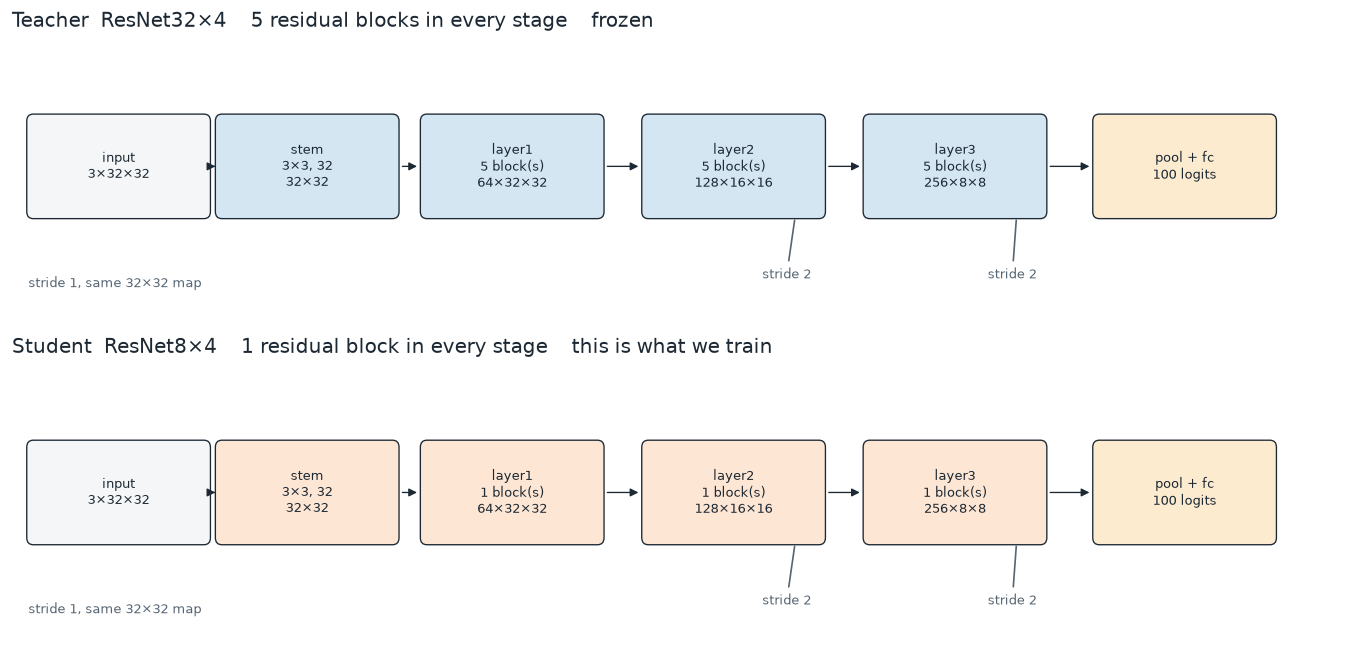

In [31]:
def draw_box(ax, xy, w, h, text, facecolor, fontsize=8):
    patch = FancyBboxPatch(
        xy, w, h,
        boxstyle="round,pad=0.02,rounding_size=0.08",
        linewidth=0.8,
        edgecolor="#1c2833",
        facecolor=facecolor,
    )
    ax.add_patch(patch)
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center", fontsize=fontsize, color="#1c2833")
    return xy[0] + w, xy[1] + h / 2

def arrow(ax, start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=10, lw=0.8, color="#1c2833"))

def draw_network(ax, title, n_blocks, color):
    ax.set_xlim(0, 16.2)
    ax.set_ylim(0, 3.2)
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, color="#1c2833")
    specs = [
        (0.2, "input\n3×32×32", "#f4f6f7"),
        (2.5, "stem\n3×3, 32\n32×32", color),
        (5.0, f"layer1\n{n_blocks} block(s)\n64×32×32", color),
        (7.7, f"layer2\n{n_blocks} block(s)\n128×16×16", color),
        (10.4, f"layer3\n{n_blocks} block(s)\n256×8×8", color),
        (13.2, "pool + fc\n100 logits", "#fdebd0"),
    ]
    centers = []
    for x, text, face in specs:
        right, mid = draw_box(ax, (x, 1.15), 2.2, 1.15, text, face)
        centers.append((x, right, mid))
    for (x0, right0, mid0), (x1, right1, mid1) in zip(centers, centers[1:]):
        arrow(ax, (right0 + 0.02, mid0), (x1 - 0.02, mid1))
    ax.text(
        0.2, 0.35,
        "stride 1, same 32×32 map" if n_blocks else "",
        fontsize=8,
        color="#566573",
    )
    ax.annotate(
        "stride 2",
        xy=(9.55, 1.15),
        xytext=(9.15, 0.45),
        fontsize=8,
        color="#566573",
        arrowprops=dict(arrowstyle="-", color="#566573"),
    )
    ax.annotate(
        "stride 2",
        xy=(12.25, 1.15),
        xytext=(11.9, 0.45),
        fontsize=8,
        color="#566573",
        arrowprops=dict(arrowstyle="-", color="#566573"),
    )

fig, axes = plt.subplots(2, 1, figsize=(11.4, 5.6))
draw_network(axes[0], "Teacher  ResNet32×4    5 residual blocks in every stage    frozen", 5, "#d4e6f1")
draw_network(axes[1], "Student  ResNet8×4    1 residual block in every stage    this is what we train", 1, "#fde6d4")
fig.tight_layout()
plt.show()


### Inside one residual block

Every block is the same pattern. Two 3×3 convolutions, each followed by batch norm.
ReLU sits between them, and again after the add. The skip connection is identity when
the shape already matches. It is a 1×1 convolution plus batch norm when the block
changes the channel count or the stride. In both of our networks that happens on the
**first** block of every stage, because the stem emits 32 channels and layer1 expects 64,
then each later stage doubles channels and (for layer2 and layer3) halves the map.

The add is what makes depth usable: the block learns a residual, `F(x)`, and the
forward value is `ReLU(F(x) + x)`. Backpropagation has a direct path along the skip,
so a stack of five teacher blocks does not have to push the gradient through ten
convolutions in series only.

DKD never attaches a loss to `F(x)`. The block diagram is here so the architecture
is concrete. The distillation loss is attached only after the final linear layer.


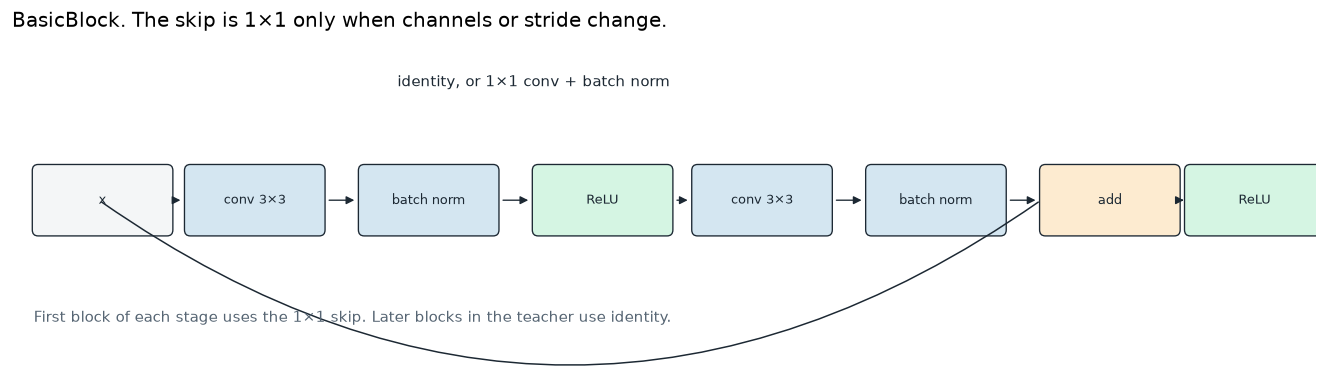

stage        teacher                student                same shape?
stem         (1, 32, 32, 32)        (1, 32, 32, 32)        True
layer1       (1, 64, 32, 32)        (1, 64, 32, 32)        True
layer2       (1, 128, 16, 16)       (1, 128, 16, 16)       True
layer3       (1, 256, 8, 8)         (1, 256, 8, 8)         True
fc           (1, 100)               (1, 100)               True


In [32]:
fig, ax = plt.subplots(figsize=(11.2, 3.2))
ax.set_xlim(0, 18)
ax.set_ylim(0, 4.2)
ax.axis("off")
ax.set_title("BasicBlock. The skip is 1×1 only when channels or stride change.", loc="left")

boxes = [
    (0.3, 1.6, "x", "#f4f6f7"),
    (2.4, 1.6, "conv 3×3", "#d4e6f1"),
    (4.8, 1.6, "batch norm", "#d4e6f1"),
    (7.2, 1.6, "ReLU", "#d5f5e3"),
    (9.4, 1.6, "conv 3×3", "#d4e6f1"),
    (11.8, 1.6, "batch norm", "#d4e6f1"),
    (14.2, 1.6, "add", "#fdebd0"),
    (16.2, 1.6, "ReLU", "#d5f5e3"),
]
rights = []
for x, y, text, face in boxes:
    right, mid = draw_box(ax, (x, y), 1.9, 0.9, text, face, fontsize=8)
    rights.append((x, right, mid))
for a, b in zip(rights, rights[1:]):
    arrow(ax, (a[1] + 0.03, a[2]), (b[0] - 0.03, b[2]))

# Skip path under the main path.
ax.annotate(
    "",
    xy=(14.2, 2.05),
    xytext=(1.2, 2.05),
    arrowprops=dict(arrowstyle="-", color="#1c2833", connectionstyle="arc3,rad=0.35", lw=0.9),
)
ax.text(7.2, 3.55, "identity, or 1×1 conv + batch norm", ha="center", fontsize=9, color="#1c2833")
ax.text(0.3, 0.45, "First block of each stage uses the 1×1 skip. Later blocks in the teacher use identity.", fontsize=9, color="#566573")
fig.tight_layout()
plt.show()

# Confirm the shapes the code really produces, rather than trusting the diagram.
probe = torch.zeros(1, 3, 32, 32)
shapes = {}

def capture(name):
    def hook(_module, _inputs, output):
        shapes[name] = tuple(output.shape)
    return hook

handles = []
for model, prefix in ((teacher, "teacher"), (student, "student")):
    handles.append(model.conv1.register_forward_hook(capture(f"{prefix}.stem")))
    handles.append(model.layer1.register_forward_hook(capture(f"{prefix}.layer1")))
    handles.append(model.layer2.register_forward_hook(capture(f"{prefix}.layer2")))
    handles.append(model.layer3.register_forward_hook(capture(f"{prefix}.layer3")))
    handles.append(model.fc.register_forward_hook(capture(f"{prefix}.fc")))
with torch.no_grad():
    teacher(probe)
    student(probe)
for handle in handles:
    handle.remove()

print(f"{'stage':<12} {'teacher':<22} {'student':<22} {'same shape?'}")
for stage in ("stem", "layer1", "layer2", "layer3", "fc"):
    a = shapes[f"teacher.{stage}"]
    b = shapes[f"student.{stage}"]
    print(f"{stage:<12} {str(a):<22} {str(b):<22} {a == b}")


### Traced with torchview

The stage diagram above was drawn so the two networks would line up. The figures below are produced by tracing a forward pass through the modules in `src/models/resnet.py`. [torchview](https://github.com/mert-kurttutan/torchview) records every module the tensor visits, including the skip connection, and Graphviz lays the graph out. Shapes on the edges are the real output shapes.

Depth 2 stops at each BasicBlock. The student figure has one block in every stage. The teacher figure has five. That length is the whole capacity gap: same widths, same resolutions, five residual units against one.

The third figure opens `student.layer2[0]`. This is the block that changes the map from 64×32×32 to 128×16×16, so the skip cannot be an identity. The left branch is the 1×1 convolution and its batch norm. The right branch is the two 3×3 convolutions. They meet at `add`, then a ReLU.

The trace is a freshly constructed module, not the loaded checkpoint. Shapes do not depend on the trained weights, and torchview's meta-device trace replaces parameter storage with placeholders. Running it on `teacher` would discard the checkpoint weights in memory.

Rendering needs the Graphviz `dot` program as well as the Python packages. On macOS that is `brew install graphviz`, then `pip install torchview graphviz`.


ResNet8x4. One BasicBlock in each stage.


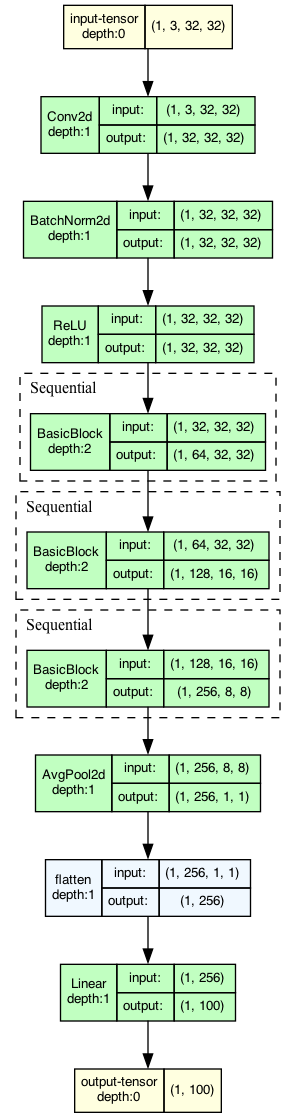

ResNet32x4. Five BasicBlocks in each stage.


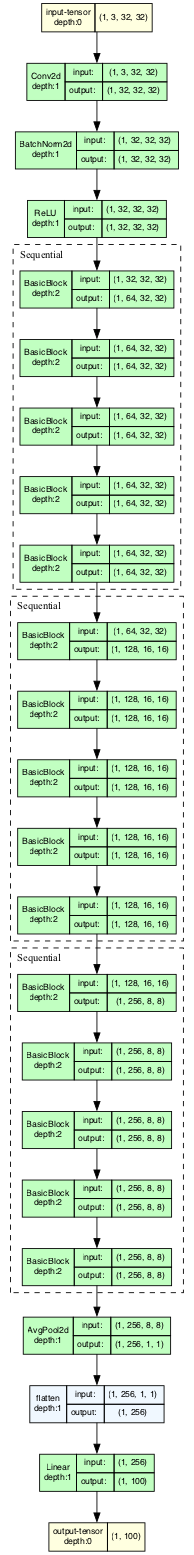

student.layer2[0]: 1x1 skip on the left, two 3x3 convolutions on the right, added, then ReLU.


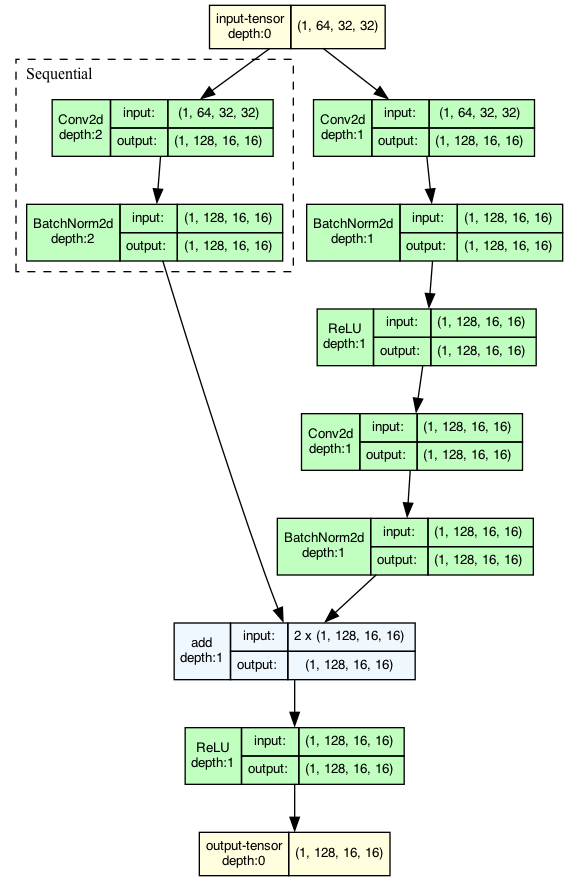

In [33]:
import os
import shutil

from IPython.display import Image, display
from torchview import draw_graph

for candidate in ("/opt/homebrew/bin", "/usr/local/bin"):
    if shutil.which("dot") is None and (Path(candidate) / "dot").exists():
        os.environ["PATH"] = candidate + os.pathsep + os.environ.get("PATH", "")
if shutil.which("dot") is None:
    raise RuntimeError("Graphviz `dot` was not found. On macOS: brew install graphviz")

def show_traced(model, input_size, name, depth):
    graph = draw_graph(
        model,
        input_size=input_size,
        graph_name=name,
        depth=depth,
        expand_nested=True,
        device="meta",
        show_shapes=True,
        hide_inner_tensors=True,
        hide_module_functions=True,
    )
    display(Image(data=graph.visual_graph.pipe(format="png")))

# Fresh modules. device='meta' replaces parameter storage with placeholders,
# so this must not be the teacher checkpoint or the 5-epoch student.
arch_student = resnet8x4()
arch_teacher = resnet32x4()
arch_block = resnet8x4().layer2[0]

print("ResNet8x4. One BasicBlock in each stage.")
show_traced(arch_student, (1, 3, 32, 32), "resnet8x4", depth=2)
print("ResNet32x4. Five BasicBlocks in each stage.")
show_traced(arch_teacher, (1, 3, 32, 32), "resnet32x4", depth=2)
print("student.layer2[0]: 1x1 skip on the left, two 3x3 convolutions on the right, added, then ReLU.")
show_traced(arch_block, (1, 64, 32, 32), "student_layer2_block0", depth=4)


The stage tensors match exactly. Block *counts* do not: the teacher's layer1 is five
BasicBlocks and the student's layer1 is one. There is no honest "block 3 of the teacher
corresponds to block 3 of the student". Feature-distillation papers invent a projection
to compare those maps anyway. DKD refuses that extra machinery. Correspondence, for
this loss, starts and ends at the 100-dimensional logit vector.

The stem filters below are the teacher's first convolution, the official checkpoint,
each drawn as a 3×3 RGB kernel. They are the only weights in the network that still
look like small edge and colour detectors. Everything after them is a mixture.


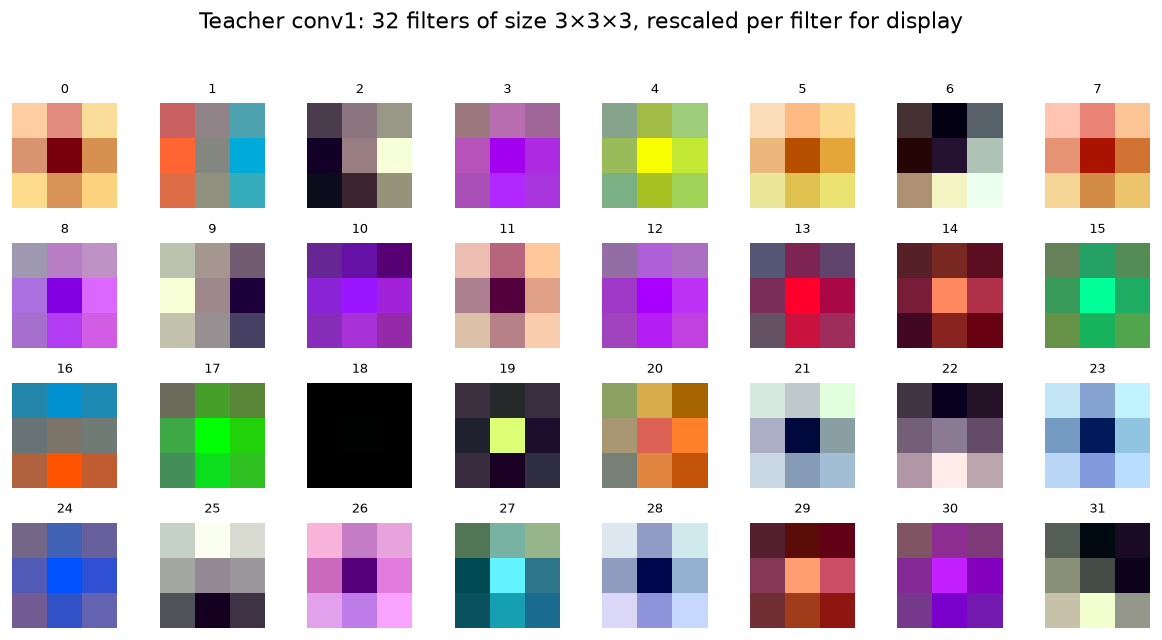

In [34]:
weight = teacher.conv1.weight.detach().cpu().numpy()  # (32, 3, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for i, ax in enumerate(axes.ravel()):
    kernel = np.transpose(weight[i], (1, 2, 0))
    kernel = kernel - kernel.min()
    kernel = kernel / max(kernel.max(), 1e-8)
    ax.imshow(kernel, interpolation="nearest")
    ax.set_title(str(i), fontsize=8)
    ax.axis("off")
fig.suptitle("Teacher conv1: 32 filters of size 3×3×3, rescaled per filter for display", y=1.02)
fig.tight_layout()
plt.show()


## 6. One held-out image through both networks

The forward pass is the same function for both objects: stem, three stages, 8×8 average pool, linear layer to 100 logits. This cell runs the frozen teacher and the student we have on disk.

The student here is the **5-epoch** DKD run in `outputs/test_5ep_dkd/`, not a finished 240-epoch model. At epoch 5 the warmup is only `5/20 = 0.25`, and the learning rate has not dropped yet. Expect the teacher to be right more often, and expect the student's probability bars to be a rough draft of the teacher's. That draft is exactly what the remaining 235 epochs are for.

Maps shown under the image are the mean over channels at the end of each stage. They are not a claim that "this unit detects wheels". They show the spatial contract: 32×32, then 16×16, then 8×8, shared by both networks, while the teacher has spent five blocks to build each map and the student has spent one.


In [35]:
N_PROBE = 1024
test_ds = CIFAR100Dataset(data["test_images"], data["test_fine"], train=False)
probe_x = torch.stack([test_ds[i][0] for i in range(N_PROBE)])
probe_y = torch.tensor([test_ds[i][1] for i in range(N_PROBE)])

def forward_batched(model, images, batch_size=128):
    pieces = []
    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            pieces.append(model(images[start:start + batch_size]))
    return torch.cat(pieces, dim=0)

teacher_logits = forward_batched(teacher, probe_x)
student_logits = forward_batched(student, probe_x)
teacher_top1 = (teacher_logits.argmax(dim=1) == probe_y).float().mean().item() * 100
student_top1 = (student_logits.argmax(dim=1) == probe_y).float().mean().item() * 100
print(f"probe size: {N_PROBE} test images (not the full 10,000)")
print(f"teacher top-1 on the probe: {teacher_top1:.2f}%")
print(f"student top-1 on the probe: {student_top1:.2f}%   [{student_source}]")
print("Chance is 1%. The published full-test figure for this teacher checkpoint is about 79.4%.")

# Prefer an image the teacher classifies correctly and is confident about, so the bars are readable.
teacher_prob_t1 = torch.softmax(teacher_logits, dim=1)
confidence = teacher_prob_t1.gather(1, probe_y.view(-1, 1)).squeeze(1)
correct = teacher_logits.argmax(dim=1) == probe_y
chosen = int(confidence.masked_fill(~correct, -1).argmax())
true_id = int(probe_y[chosen])
print(
    "chosen probe index", chosen,
    "true class", fine_names[true_id],
    "teacher confidence at T=1", round(float(confidence[chosen]), 3),
    "student argmax", fine_names[int(student_logits[chosen].argmax())],
)


probe size: 1024 test images (not the full 10,000)
teacher top-1 on the probe: 79.69%
student top-1 on the probe: 41.41%   [5-epoch DKD checkpoint (ckpt_best.pth, epoch 5)]
Chance is 1%. The published full-test figure for this teacher checkpoint is about 79.4%.
chosen probe index 91 true class caterpillar teacher confidence at T=1 1.0 student argmax television


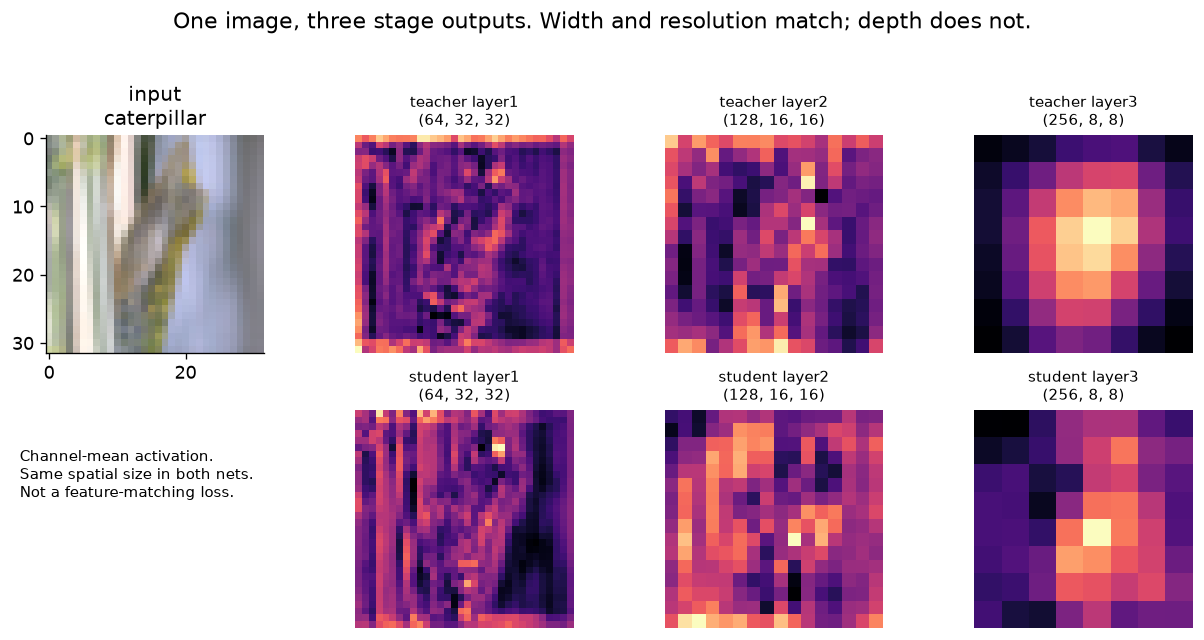

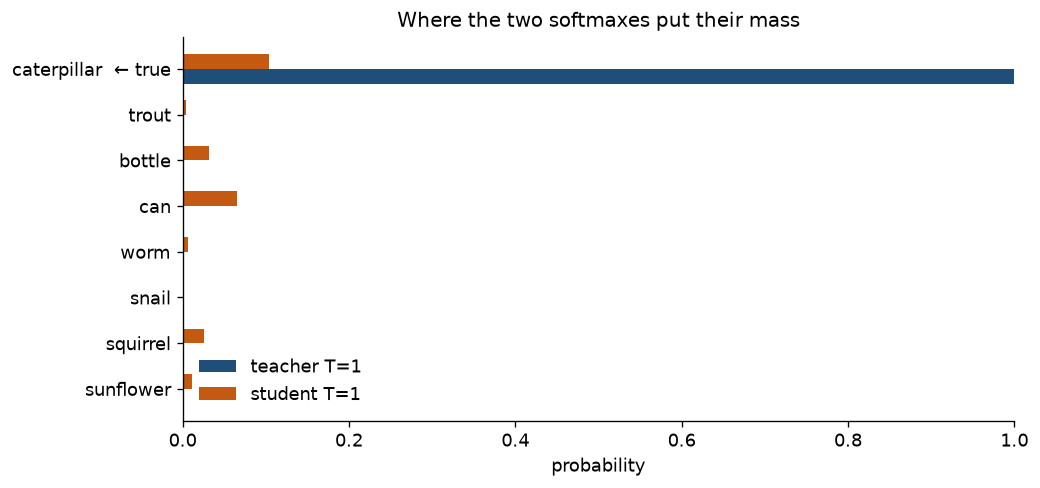

In [36]:
record = {}

def keep(name):
    def hook(_module, _inputs, output):
        record[name] = output.detach()
    return hook

hooks = []
for model, prefix in ((teacher, "teacher"), (student, "student")):
    hooks.append(model.layer1.register_forward_hook(keep(f"{prefix}.layer1")))
    hooks.append(model.layer2.register_forward_hook(keep(f"{prefix}.layer2")))
    hooks.append(model.layer3.register_forward_hook(keep(f"{prefix}.layer3")))

image = probe_x[chosen:chosen + 1]
with torch.no_grad():
    t_logits = teacher(image)
    s_logits = student(image)
for hook in hooks:
    hook.remove()

rgb = np.transpose(image.numpy()[0], (1, 2, 0)) * CIFAR100_STD + CIFAR100_MEAN
rgb = np.clip(rgb, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(10.6, 5.2))
axes[0, 0].imshow(rgb)
axes[0, 0].set_title(f"input\n{fine_names[true_id]}")
axes[1, 0].axis("off")
axes[1, 0].text(0.0, 0.6, "Channel-mean activation.\nSame spatial size in both nets.\nNot a feature-matching loss.", fontsize=9, transform=axes[1, 0].transAxes)

for col, stage in enumerate(("layer1", "layer2", "layer3"), start=1):
    for row, prefix in enumerate(("teacher", "student")):
        act = record[f"{prefix}.{stage}"][0].mean(dim=0).numpy()
        im = axes[row, col].imshow(act, cmap="magma")
        axes[row, col].set_title(f"{prefix} {stage}\n{tuple(record[f'{prefix}.{stage}'].shape[1:])}", fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("One image, three stage outputs. Width and resolution match; depth does not.", y=1.02)
fig.tight_layout()
plt.show()

def top_table(logits, k=8):
    prob = torch.softmax(logits[0], dim=0)
    values, index = torch.topk(prob, k)
    return [(fine_names[int(i)], float(v)) for v, i in zip(values, index)]

teacher_top = top_table(t_logits)
student_top = top_table(s_logits)
# Union of the names, with the true class pinned first, so the two bars share an axis.
order = [fine_names[true_id]]
for name, _ in teacher_top + student_top:
    if name not in order:
        order.append(name)
order = order[:8]
teacher_map = dict(top_table(t_logits, k=100))
student_map = dict(top_table(s_logits, k=100))

fig, ax = plt.subplots(figsize=(8.8, 4.2))
ypos = np.arange(len(order))
ax.barh(ypos + 0.16, [teacher_map[n] for n in order], height=0.32, color=TEACHER_COLOR, label="teacher T=1")
ax.barh(ypos - 0.16, [student_map[n] for n in order], height=0.32, color=STUDENT_COLOR, label="student T=1")
ax.set_yticks(ypos, [n + ("  ← true" if n == fine_names[true_id] else "") for n in order])
ax.invert_yaxis()
ax.set_xlabel("probability")
ax.set_xlim(0, 1)
ax.set_title("Where the two softmaxes put their mass")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


Read the bars as two different jobs, which is the split from section 2:

- The height on the **true** class is what cross-entropy and TCKD care about.
- The heights on the **other** classes, after they are renormalised to sum to 1, are what NCKD cares about.

If the student puts its leftover mass on a different superclass than the teacher, NCKD is large even when both models name the true class correctly. That is the usual situation early in training, and it is visible in a 5-epoch student.

Nothing in this forward pass compares `layer2` of the teacher with `layer2` of the student. The hooks were for us, not for the loss.


## 7. How the teacher and the student interact

One training step, in the order `train_one_epoch` actually runs it:

1. The same augmented batch goes into both networks.
2. The student is in train mode. Its forward pass also updates BatchNorm running statistics.
3. The teacher is in eval mode, inside `torch.no_grad()`, and every teacher parameter has `requires_grad` set to false. It contributes logits and nothing else.
4. `DistillationLoss` builds `CE + distillation` from the two logit tensors and the integer labels.
5. `loss.backward()` fills `.grad` on the student only.
6. SGD steps the student. The teacher weights are bitwise unchanged.

There is one student forward and one teacher forward. DKD does not add a second pass, a memory bank, or a projector. The timing benchmark in `benchmark_batch_latency` exists to show that the five loss modes cost about the same, because the expensive part is the two forwards, which they share.


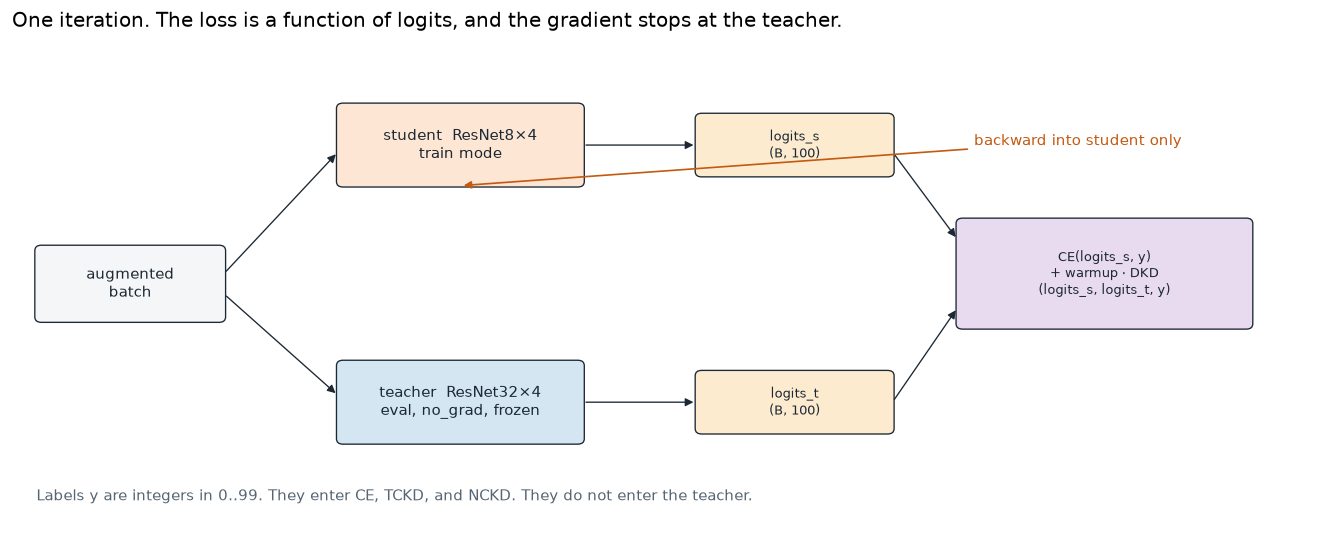

teacher parameters with requires_grad: 0
student parameters with requires_grad: 32 of 32


In [37]:
fig, ax = plt.subplots(figsize=(11.2, 4.6))
ax.set_xlim(0, 16)
ax.set_ylim(0, 7.2)
ax.axis("off")
ax.set_title("One iteration. The loss is a function of logits, and the gradient stops at the teacher.", loc="left")

draw_box(ax, (0.3, 3.0), 2.3, 1.1, "augmented\nbatch", "#f4f6f7", fontsize=9)
draw_box(ax, (4.0, 5.0), 3.0, 1.2, "student  ResNet8×4\ntrain mode", "#fde6d4", fontsize=9)
draw_box(ax, (4.0, 1.2), 3.0, 1.2, "teacher  ResNet32×4\neval, no_grad, frozen", "#d4e6f1", fontsize=9)
draw_box(ax, (8.4, 5.15), 2.4, 0.9, "logits_s\n(B, 100)", "#fdebd0", fontsize=8)
draw_box(ax, (8.4, 1.35), 2.4, 0.9, "logits_t\n(B, 100)", "#fdebd0", fontsize=8)
draw_box(ax, (11.6, 2.9), 3.6, 1.6, "CE(logits_s, y)\n+ warmup · DKD\n(logits_s, logits_t, y)", "#e8daef", fontsize=8)

arrow(ax, (2.6, 3.7), (4.0, 5.5))
arrow(ax, (2.6, 3.4), (4.0, 1.9))
arrow(ax, (7.0, 5.6), (8.4, 5.6))
arrow(ax, (7.0, 1.8), (8.4, 1.8))
arrow(ax, (10.8, 5.5), (11.6, 4.2))
arrow(ax, (10.8, 1.8), (11.6, 3.2))
ax.annotate(
    "backward into student only",
    xy=(5.5, 5.0),
    xytext=(11.8, 5.6),
    fontsize=9,
    color=STUDENT_COLOR,
    arrowprops=dict(arrowstyle="-|>", color=STUDENT_COLOR, lw=1.0),
)
ax.text(0.3, 0.35, "Labels y are integers in 0..99. They enter CE, TCKD, and NCKD. They do not enter the teacher.", fontsize=9, color="#566573")
fig.tight_layout()
plt.show()

print("teacher parameters with requires_grad:", sum(p.requires_grad for p in teacher.parameters()))
print("student parameters with requires_grad:", sum(p.requires_grad for p in student.parameters()), "of", sum(1 for _ in student.parameters()))


## 8. The loss on a real batch, not on three made-up logits

The 3-class example was there to trust the algebra. This section runs the same functions on the probe: real teacher logits, real 5-epoch student logits, real CIFAR-100 labels.

For each image we record, at the training temperature T=4:

- `p_t` of the teacher, the mass on the true class;
- the classical multiplier `1 - p_t`;
- TCKD and NCKD before the `T^2` rescaling;
- the piece of NCKD that classical KD keeps, `(1 - p_t) * NCKD`;
- the piece DKD uses, `β * NCKD` with β=8.

`T^2 = 16` multiplies every distillation term equally, so it does not change the comparison between the two multipliers.

Read the T=4 histogram against the T=1 toy, not instead of it. Temperature 4 flattens the teacher, so the average classical multiplier `(1 - p_t)` is no longer tiny. The damage in the 3-class example was a multiplier of 0.06. On this probe the average multiplier at T=4 is much closer to 1, and β=8 is then mostly a large constant gain on NCKD. What classical KD still cannot do is choose that gain separately from the per-image confidence. The left-hand histogram is there to show both temperatures at once.


temperature T=4.0,  T^2=16.0
mean teacher p_t at T=1:            0.760   fraction above 0.5: 0.769
mean teacher p_t at T=4:            0.175   fraction above 0.5: 0.031
mean classical multiplier at T=4:   0.825
mean TCKD:                          0.198
mean NCKD:                          0.112
mean (1-p_t)*NCKD:                  0.093
mean β*NCKD:                        0.894
ratio of mean NCKD weight, DKD / classical: 9.57


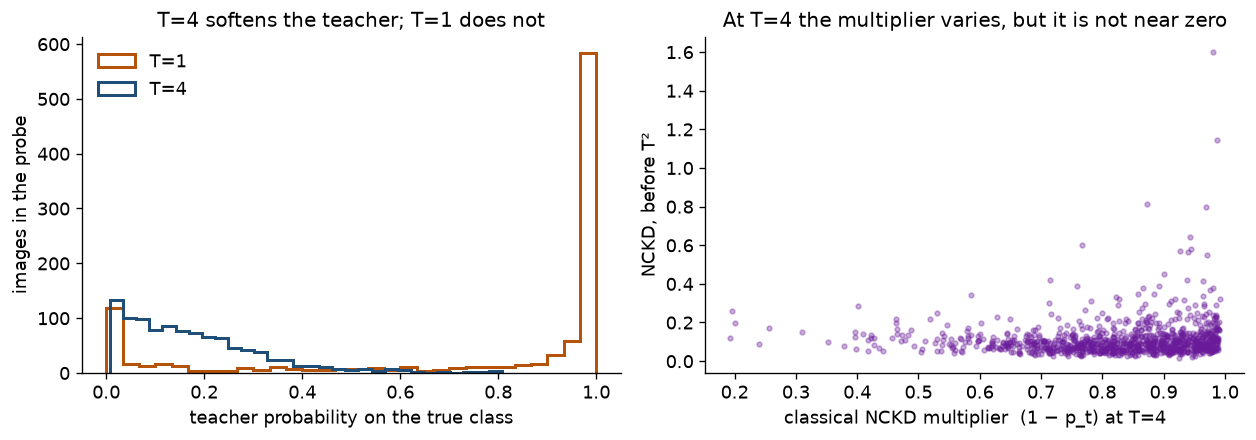

In [38]:
T = 4.0
BETA = 8.0
tckd_i = tckd_per_sample(student_logits, teacher_logits, probe_y, temperature=T)
nckd_i = nckd_per_sample(student_logits, teacher_logits, probe_y, temperature=T)
pt = torch.softmax(teacher_logits / T, dim=1).gather(1, probe_y.view(-1, 1)).squeeze(1)
pt_sharp = torch.softmax(teacher_logits, dim=1).gather(1, probe_y.view(-1, 1)).squeeze(1)
classical_nckd = (1 - pt) * nckd_i
dkd_nckd = BETA * nckd_i

print(f"temperature T={T},  T^2={T**2}")
print(f"mean teacher p_t at T=1:            {pt_sharp.mean():.3f}   fraction above 0.5: {(pt_sharp > 0.5).float().mean():.3f}")
print(f"mean teacher p_t at T=4:            {pt.mean():.3f}   fraction above 0.5: {(pt > 0.5).float().mean():.3f}")
print(f"mean classical multiplier at T=4:   {(1 - pt).mean():.3f}")
print(f"mean TCKD:                          {tckd_i.mean():.3f}")
print(f"mean NCKD:                          {nckd_i.mean():.3f}")
print(f"mean (1-p_t)*NCKD:                  {classical_nckd.mean():.3f}")
print(f"mean β*NCKD:                        {dkd_nckd.mean():.3f}")
print(
    "ratio of mean NCKD weight, DKD / classical:",
    round(float(dkd_nckd.mean() / classical_nckd.mean()), 2),
)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.8))
axes[0].hist(pt_sharp.numpy(), bins=30, histtype="step", lw=1.8, color=ACCENT, label="T=1")
axes[0].hist(pt.numpy(), bins=30, histtype="step", lw=1.8, color=TEACHER_COLOR, label="T=4")
axes[0].set_xlabel("teacher probability on the true class")
axes[0].set_ylabel("images in the probe")
axes[0].set_title("T=4 softens the teacher; T=1 does not")
axes[0].legend(frameon=False)
axes[1].scatter((1 - pt).numpy(), nckd_i.numpy(), s=8, alpha=0.35, color=NCKD_COLOR)
axes[1].set_xlabel("classical NCKD multiplier  (1 − p_t) at T=4")
axes[1].set_ylabel("NCKD, before T²")
axes[1].set_title("At T=4 the multiplier varies, but it is not near zero")
fig.tight_layout()
plt.show()


In [39]:
# Same batch, five modes, full warmup (epoch >= 20) and early warmup (epoch 1).
logits_s = student_logits[:128].detach()
logits_t = teacher_logits[:128].detach()
labels = probe_y[:128]

def report(epoch):
    print(f"epoch {epoch}  (warmup factor {warmup_factor(epoch, 20):.2f})")
    print(f"  {'mode':<12} {'total':>8} {'ce':>8} {'distill':>8}")
    for mode in ("ce", "kd", "tckd_only", "nckd_only", "dkd"):
        out = DistillationLoss(mode=mode, alpha=1.0, beta=8.0, temperature=4.0, warmup_epochs=20)(
            logits_s, labels, logits_t, epoch=epoch
        )
        print(
            f"  {mode:<12} {out['loss'].item():8.3f} {out['loss_ce'].item():8.3f} {out['loss_distill'].item():8.3f}"
        )

report(1)
print()
report(20)

# Identity on this real batch, not just the 3-class toy.
kd_value = kd_loss(logits_s.double(), logits_t.double(), temperature=4.0)
kd_from_parts = kd_loss_from_decoupled_terms(logits_s.double(), logits_t.double(), labels, temperature=4.0)
print()
print(f"classical KD on 128 images:     {kd_value.item():.6f}")
print(f"TCKD + (1-p_t)*NCKD, times T^2: {kd_from_parts.item():.6f}")
print(f"absolute gap:                   {abs(kd_value.item() - kd_from_parts.item()):.3e}")


epoch 1  (warmup factor 0.05)
  mode            total       ce  distill
  ce              2.284    2.284    0.000
  kd              7.219    2.284    4.935
  tckd_only       2.457    2.284    0.174
  nckd_only       3.002    2.284    0.719
  dkd             3.176    2.284    0.893

epoch 20  (warmup factor 1.00)
  mode            total       ce  distill
  ce              2.284    2.284    0.000
  kd              7.219    2.284    4.935
  tckd_only       5.760    2.284    3.477
  nckd_only      16.662    2.284   14.379
  dkd            20.139    2.284   17.855

classical KD on 128 images:     4.935141
TCKD + (1-p_t)*NCKD, times T^2: 4.935141
absolute gap:                   8.882e-16


Two facts from that table are easy to miss in the paper and obvious in the code.

**Warmup multiplies only the decoupled modes.** At epoch 1 the factor is `1/20 = 0.05`, so DKD, TCKD-only, and NCKD-only are almost just cross-entropy. Classical KD in our `DistillationLoss` is not warmed up; it enters at full strength. By epoch 20 the factor is 1 and stays there. This is the mdistiller DKD schedule, copied on purpose.

**CE does not depend on the teacher.** It is identical in every row. Switching mode cannot change the hard-label term, only the distill column. That is the ablation: four students, one difference.

The identity check at the bottom is the same algebra as section 2, now at T=4 on CIFAR-100 logits. The gap should be numerical noise. If it ever is not, the implementation has drifted from the paper.


## 9. Hyperparameters, and what each one actually moves

These knobs are not interchangeable.

| Knob | Value we train with | What it changes |
| --- | --- | --- |
| T | 4 | Divides logits before every softmax. Larger T makes both distributions softer, so NCKD sees more of the tail. `T^2` then rescales the loss so the gradient does not shrink just because the probabilities got flatter. |
| α | 1 | Weight on TCKD, the binary confidence term. |
| β | 8 | Weight on NCKD, replacing `(1 - p_t)`. This is the knob the paper tunes. |
| warmup | 20 epochs, linear | Ramps α/β from a small value so a randomly initialised student is not immediately punished for disagreeing with a strong teacher. |
| lr | 0.05, ×0.1 at 150, 180, 210 | Step size on the student. Independent of the loss split. |
| CE weight | 1 | Leaves the hard label in the objective. DKD is added to CE, not substituted for it. |

The plots below are **loss surfaces on a fixed batch of logits**. They are not accuracy surfaces. Changing β changes the number that `backward` sees; whether that raises the test score is what the 240-epoch runs are for. The paper's ablation, for this exact pair, is the reason β=8 is in the config: classical KD at 73.63, decoupling with β=1 at 74.79, and β=8 at 76.32. Those are their averages, not numbers this notebook measures.

The α/β grid in this section is an interactive Plotly heatmap. Hover a cell to read the loss. The open marker is the training point, α=1 and β=8.


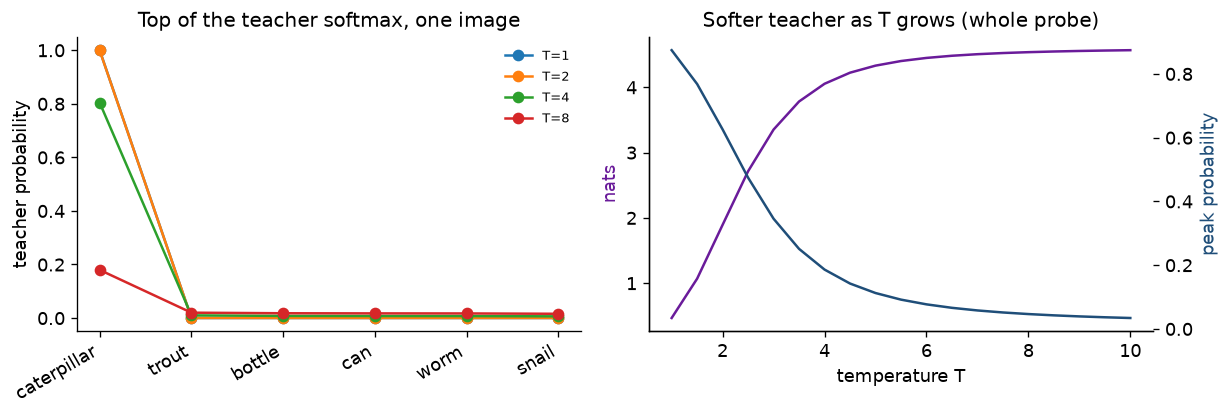

Training uses T=4, marked by the recipe rather than by a peak on this curve.


In [40]:
# Temperature on the chosen image: same class order at every T, so the curves are comparable.
base_logits = teacher_logits[chosen].numpy()
order = np.argsort(base_logits)[::-1][:6]
temperatures = [1, 2, 4, 8]
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6))
for temperature in temperatures:
    z = base_logits / temperature
    z = z - z.max()
    prob = np.exp(z)
    prob = prob / prob.sum()
    axes[0].plot(np.arange(6), prob[order], marker="o", label=f"T={temperature}")
axes[0].set_xticks(np.arange(6), [fine_names[int(i)] for i in order], rotation=30, ha="right")
axes[0].set_ylabel("teacher probability")
axes[0].set_title("Top of the teacher softmax, one image")
axes[0].legend(frameon=False, fontsize=8)

entropies = []
peak = []
for temperature in np.linspace(1, 10, 19):
    z = teacher_logits.numpy() / temperature
    z = z - z.max(axis=1, keepdims=True)
    prob = np.exp(z)
    prob = prob / prob.sum(axis=1, keepdims=True)
    entropies.append(float(-(prob * np.log(prob + 1e-12)).sum(axis=1).mean()))
    peak.append(float(prob.max(axis=1).mean()))
ax2 = axes[1]
ax2.plot(np.linspace(1, 10, 19), entropies, color=NCKD_COLOR, label="mean entropy")
ax2.set_xlabel("temperature T")
ax2.set_ylabel("nats", color=NCKD_COLOR)
ax2b = ax2.twinx()
ax2b.plot(np.linspace(1, 10, 19), peak, color=TEACHER_COLOR, label="mean peak probability")
ax2b.set_ylabel("peak probability", color=TEACHER_COLOR)
ax2b.spines["top"].set_visible(False)
ax2.set_title("Softer teacher as T grows (whole probe)")
fig.tight_layout()
plt.show()
print("Training uses T=4, marked by the recipe rather than by a peak on this curve.")


In [41]:
# alpha / beta grid on the first 128 probe images, at full warmup, distillation term only.
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "plotly_mimetype"

alphas = [0.0, 0.5, 1.0, 2.0, 4.0]
betas = [0.0, 1.0, 2.0, 4.0, 8.0, 16.0]
grid = np.zeros((len(alphas), len(betas)))
with torch.no_grad():
    tckd_mean = tckd_per_sample(logits_s, logits_t, labels, temperature=4.0).mean()
    nckd_mean = nckd_per_sample(logits_s, logits_t, labels, temperature=4.0).mean()
    for i, alpha in enumerate(alphas):
        for j, beta in enumerate(betas):
            grid[i, j] = float((alpha * tckd_mean + beta * nckd_mean) * 16.0)

heat = go.Heatmap(
    z=grid,
    x=betas,
    y=alphas,
    colorscale="YlOrBr",
    text=[[f"{value:.1f}" for value in row] for row in grid],
    texttemplate="%{text}",
    colorbar={"title": "(α·TCKD + β·NCKD)·T²"},
    hovertemplate="α=%{y}<br>β=%{x}<br>loss=%{z:.2f}<extra></extra>",
)
marker = go.Scatter(
    x=[8.0],
    y=[1.0],
    mode="markers",
    marker={"size": 18, "color": "black", "symbol": "circle-open"},
    name="training point α=1, β=8",
    hovertemplate="training point<br>α=1, β=8<extra></extra>",
)
fig = go.Figure(data=[heat, marker])
fig.update_layout(
    title="Distillation loss on a frozen 128-image batch",
    xaxis_title="β  (NCKD weight)",
    yaxis_title="α  (TCKD weight)",
    width=740,
    height=460,
    margin={"l": 60, "r": 20, "t": 50, "b": 50},
)
fig.update_yaxes(autorange="reversed")
fig.show()
print(
    f"Training point α=1, β=8 has loss {grid[alphas.index(1.0), betas.index(8.0)]:.2f}. "
    "Moving right weights dark knowledge more. Moving up weights binary confidence more."
)


Training point α=1, β=8 has loss 17.86. Moving right weights dark knowledge more. Moving up weights binary confidence more.


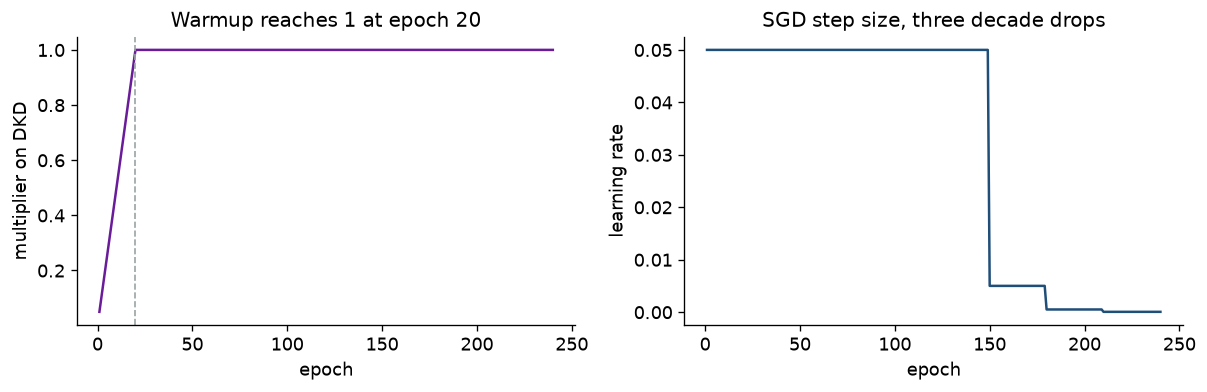

lr at epochs 1, 150, 180, 210: [0.05, 0.005000000000000001, 0.0005000000000000001, 5.0000000000000016e-05]


In [42]:
epochs = np.arange(1, 241)
warm = np.array([warmup_factor(int(e), 20) for e in epochs])

# Use the real schedule function. It writes into an optimizer, so the optimizer is a throwaway.
throwaway = resnet8x4()
opt = build_optimizer(throwaway, lr=0.05, momentum=0.9, weight_decay=5e-4)
lrs = [adjust_learning_rate(opt, int(e), base_lr=0.05, decay_stages=[150, 180, 210], decay_rate=0.1) for e in epochs]

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.4))
axes[0].plot(epochs, warm, color=NCKD_COLOR)
axes[0].axvline(20, color="#99a3a4", ls="--", lw=1)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("multiplier on DKD")
axes[0].set_title("Warmup reaches 1 at epoch 20")
axes[1].plot(epochs, lrs, color=TEACHER_COLOR)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("learning rate")
axes[1].set_title("SGD step size, three decade drops")
fig.tight_layout()
plt.show()
print("lr at epochs 1, 150, 180, 210:", [lrs[e - 1] for e in (1, 150, 180, 210)])


## 10. Backpropagation, with the gradient actually computed

The computational graph for one step has two roots that look similar and are not.

```text
image ──► student parameters ──► logits_s ──► CE ──► loss
                                  logits_s ──► TCKD, NCKD ──► loss
image ──► teacher parameters ──► logits_t ──► TCKD, NCKD
```

`loss.backward()` walks every edge whose tensors require grad. The teacher edge is cut twice: `torch.no_grad()` does not even record it, and `requires_grad_(False)` would drop it anyway. The label is an integer tensor, so it is not a differentiable input. The graph that remains is: scalar loss, into the student logits, back through the linear layer, the pool, the three stages, and the stem, including along each residual skip.

Two views of that gradient are below.

**Logit space.** Detach the student logits and mark them as the leaf. Then the gradient of the loss with respect to those 100 numbers answers: "which classes is this loss trying to push?" Classical KD and DKD see the same teacher and the same student. They disagree on how hard to push the non-target classes when the teacher is confident.

**Parameter space.** A real backward through a copy of the student, in eval mode so this demo does not touch the checkpoint's BatchNorm buffers. The plot is the L2 norm of the gradient in each stage. It should be nonzero from `fc` down through `stem` for the student, and there should be nothing to show for the teacher.


focus image 91: true class caterpillar, teacher p_t at T=1 is 1.000, at T=4 is 0.804


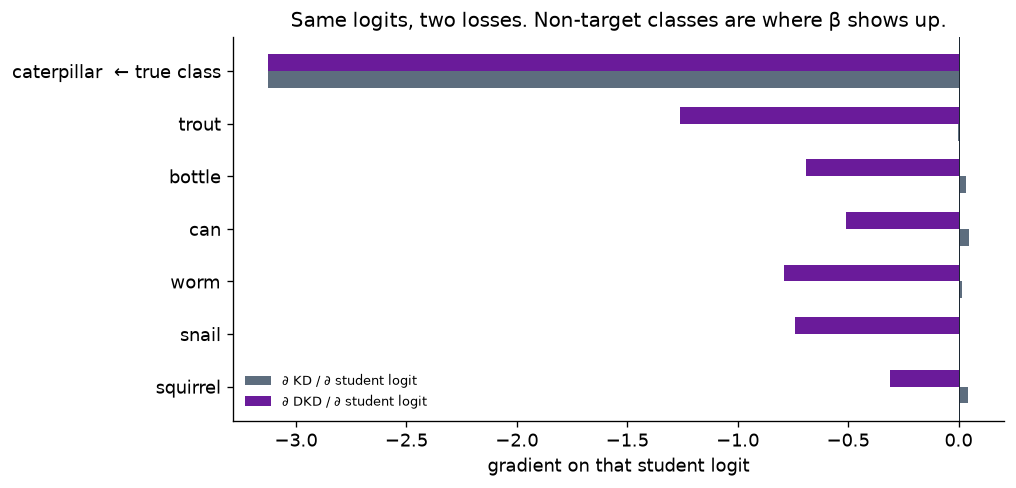

L2 of the gradient on the 99 non-target logits:  KD 0.3442    DKD 2.7588
A negative gradient on the true-class logit pushes that logit up. The non-target gradients reshape the dark knowledge.


In [43]:
# The most confident teacher image in the probe makes the coupling easiest to see.
sharp = torch.softmax(teacher_logits, dim=1)
sharp_pt = sharp.gather(1, probe_y.view(-1, 1)).squeeze(1)
focus = int(sharp_pt.argmax())
focus_name = fine_names[int(probe_y[focus])]
print(
    f"focus image {focus}: true class {focus_name}, "
    f"teacher p_t at T=1 is {float(sharp_pt[focus]):.3f}, "
    f"at T=4 is {float(pt[focus]):.3f}"
)

leaf = student_logits[focus:focus + 1].detach().clone().requires_grad_(True)
teacher_one = teacher_logits[focus:focus + 1].detach()
label_one = probe_y[focus:focus + 1]

loss_kd = kd_loss(leaf, teacher_one, temperature=4.0)
loss_dkd = dkd_loss(leaf, teacher_one, label_one, alpha=1.0, beta=8.0, temperature=4.0)
grad_kd, = torch.autograd.grad(loss_kd, leaf, retain_graph=False)
# New leaf, same values, so the two gradients are independent.
leaf2 = student_logits[focus:focus + 1].detach().clone().requires_grad_(True)
loss_dkd = dkd_loss(leaf2, teacher_one, label_one, alpha=1.0, beta=8.0, temperature=4.0)
grad_dkd, = torch.autograd.grad(loss_dkd, leaf2)

target_index = int(label_one)
# Show the true class plus the teacher's strongest alternatives.
show_idx = [target_index]
for class_id in torch.topk(sharp[focus], 7).indices.tolist():
    if class_id not in show_idx:
        show_idx.append(class_id)
show_idx = show_idx[:7]

fig, ax = plt.subplots(figsize=(8.6, 4.2))
ypos = np.arange(len(show_idx))
ax.barh(ypos + 0.16, [grad_kd[0, i].item() for i in show_idx], height=0.32, color="#5d6d7e", label="∂ KD / ∂ student logit")
ax.barh(ypos - 0.16, [grad_dkd[0, i].item() for i in show_idx], height=0.32, color=NCKD_COLOR, label="∂ DKD / ∂ student logit")
labels_y = []
for i in show_idx:
    tag = "  ← true class" if i == target_index else ""
    labels_y.append(fine_names[i] + tag)
ax.set_yticks(ypos, labels_y)
ax.invert_yaxis()
ax.axvline(0, color="#1c2833", lw=0.6)
ax.set_xlabel("gradient on that student logit")
ax.set_title("Same logits, two losses. Non-target classes are where β shows up.")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

nontarget = [i for i in range(100) if i != target_index]
kd_nt = grad_kd[0, nontarget].norm().item()
dkd_nt = grad_dkd[0, nontarget].norm().item()
print(f"L2 of the gradient on the 99 non-target logits:  KD {kd_nt:.4f}    DKD {dkd_nt:.4f}")
print("A negative gradient on the true-class logit pushes that logit up. The non-target gradients reshape the dark knowledge.")


teacher parameters that received a gradient: 0


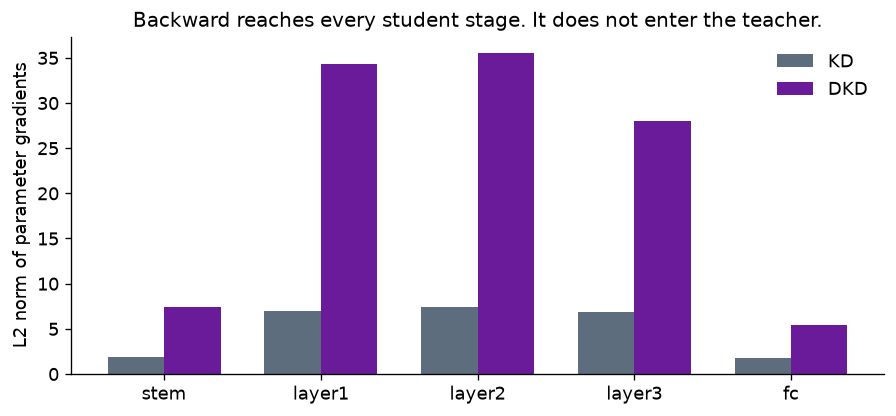

In [44]:
import copy

demo_student = copy.deepcopy(student).eval()
for p in demo_student.parameters():
    p.requires_grad_(True)
demo_teacher = teacher  # already frozen

batch_x = probe_x[:32]
batch_y = probe_y[:32]

def stage_of(name):
    for stage in ("layer1", "layer2", "layer3", "fc"):
        if name.startswith(stage):
            return stage
    return "stem"

def stage_grad_norms(model):
    buckets = {key: 0.0 for key in ("stem", "layer1", "layer2", "layer3", "fc")}
    for name, param in model.named_parameters():
        if param.grad is None:
            continue
        buckets[stage_of(name)] += float(param.grad.detach().pow(2).sum())
    return {key: value ** 0.5 for key, value in buckets.items()}

norms = {}
for mode in ("kd", "dkd"):
    demo_student.zero_grad(set_to_none=True)
    logits_student = demo_student(batch_x)
    with torch.no_grad():
        logits_teacher = demo_teacher(batch_x)
    out = DistillationLoss(mode=mode, alpha=1.0, beta=8.0, temperature=4.0, warmup_epochs=20)(
        logits_student, batch_y, logits_teacher, epoch=20
    )
    out["loss"].backward()
    norms[mode] = stage_grad_norms(demo_student)

teacher_grad_params = sum(p.grad is not None for p in demo_teacher.parameters())
print("teacher parameters that received a gradient:", teacher_grad_params)

stages = ["stem", "layer1", "layer2", "layer3", "fc"]
fig, ax = plt.subplots(figsize=(7.6, 3.6))
xpos = np.arange(len(stages))
ax.bar(xpos - 0.18, [norms["kd"][s] for s in stages], width=0.36, color="#5d6d7e", label="KD")
ax.bar(xpos + 0.18, [norms["dkd"][s] for s in stages], width=0.36, color=NCKD_COLOR, label="DKD")
ax.set_xticks(xpos, stages)
ax.set_ylabel("L2 norm of parameter gradients")
ax.set_title("Backward reaches every student stage. It does not enter the teacher.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### The backward graph of the loss

[torchviz](https://github.com/szagoruyko/pytorchviz) draws the autograd graph: the path `loss.backward()` actually walks. The figure is the DKD training objective on one image, with the student logits as the only leaf. The ResNet is not in this picture. The teacher logits were computed under `torch.no_grad()`, so they do not appear.

Three branches leave the student logits and meet at the final add:

- `NllLossBackward` is the hard-label cross-entropy.
- The branch that concatenates two probabilities (`CatBackward`) and then takes a log is TCKD, the binary KL.
- The `LogSoftmaxBackward` branch is NCKD, the KL on the non-target classes after the true class has been masked.

The node names are PyTorch's backward kernels, not the names in `src/losses/dkd.py`. The structure is the same one the logit-gradient plot just measured.


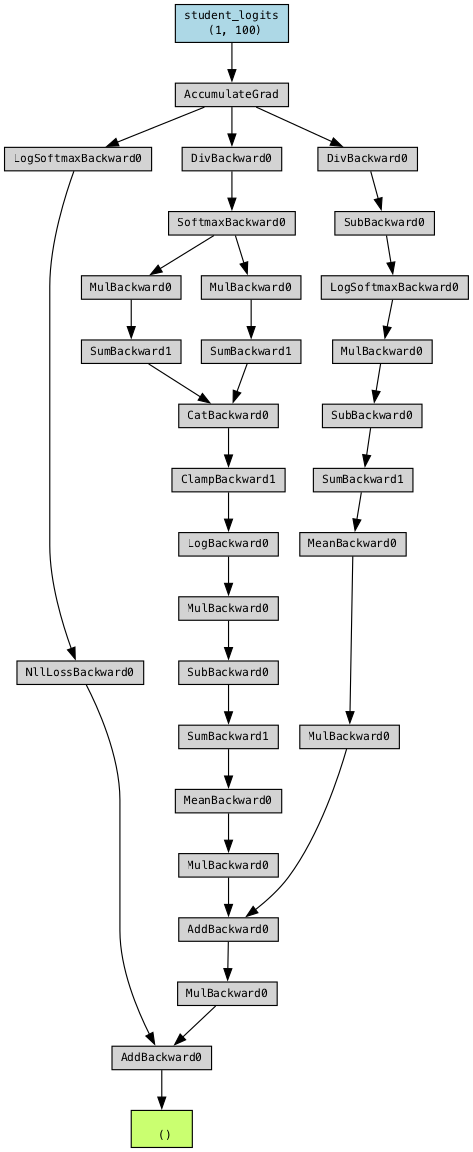

scalar loss on this image: 76.6363
The teacher logits are a constant. The only arrow into the graph is student_logits.


In [45]:
from torchviz import make_dot

leaf = student_logits[focus:focus + 1].detach().clone().requires_grad_(True)
loss = F.cross_entropy(leaf, probe_y[focus:focus + 1]) + dkd_loss(
    leaf,
    teacher_logits[focus:focus + 1].detach(),
    probe_y[focus:focus + 1],
    alpha=1.0,
    beta=8.0,
    temperature=4.0,
)
graph = make_dot(loss, params={"student_logits": leaf})
display(Image(data=graph.pipe(format="png")))
print(f"scalar loss on this image: {float(loss.detach()):.4f}")
print("The teacher logits are a constant. The only arrow into the graph is student_logits.")


How to read the stage plot without over-claiming. The bars are not five independent learning rates.
A large norm in `layer3` and a smaller one in `stem` is the usual shape of a residual network:
the loss is attached at the logits, so the last linear layer and the last stage sit next to it,
and the stem sees a gradient that has been averaged through the skips and the later blocks.
What the plot is for is the cut. If a teacher bar appeared, the freeze would be broken.

The logit plot is the one that matches the algebra. DKD's extra weight β lands on the
non-target coordinates. That is the gradient form of "stop multiplying NCKD by `(1 - p_t)`".


## 11. What training has already done

Full protocol: 240 epochs, batch size 64, about 781 steps per epoch on the 50,000 training images.
Checkpoints and a `metrics.jsonl` row per epoch land in `outputs/<mode>/`.

On disk right now, the run long enough to read is `outputs/test_5ep_dkd`: five epochs of DKD
on the full training set. It is a prefix of the real schedule, not a result to compare with 76.32.
At epoch 5 the learning rate is still 0.05 and the distillation warmup is 0.25.

The logged `train_loss_distill` can rise across these epochs while the student is getting
better. Divide it by the warmup factor before concluding that the distillation term got worse.
The underlying DKD term is what is left after that division. Cross-entropy, which has no warmup,
should fall.


epoch   warmup       ce  distill   distill/warmup  test top1
    1     0.05    3.988    1.120           22.399     13.73%
    2     0.10    3.307    2.008           20.084     24.24%
    3     0.15    2.747    2.694           17.960     29.07%
    4     0.20    2.371    3.301           16.505     39.25%
    5     0.25    2.129    3.864           15.455     41.02%


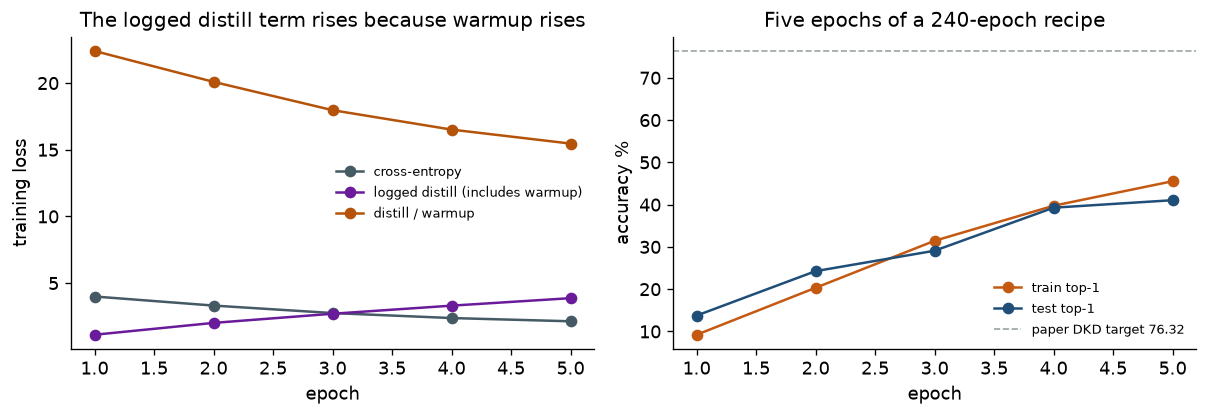

In [46]:
def read_jsonl(path):
    path = Path(path)
    if not path.exists():
        return []
    rows = []
    for line in path.read_text().splitlines():
        if line.strip():
            rows.append(json.loads(line))
    return rows

rows = read_jsonl(REPO / "outputs" / "test_5ep_dkd" / "metrics.jsonl")
if not rows:
    print("No 5-epoch log at outputs/test_5ep_dkd/metrics.jsonl yet.")
else:
    ep = np.array([r["epoch"] for r in rows])
    ce = np.array([r["train_loss_ce"] for r in rows])
    distill = np.array([r["train_loss_distill"] for r in rows])
    warm = np.array([warmup_factor(int(e), 20) for e in ep])
    underlying = distill / warm
    train_acc = np.array([r["train_top1"] for r in rows])
    test_acc = np.array([r["test_top1"] for r in rows])

    print(f"{'epoch':>5} {'warmup':>8} {'ce':>8} {'distill':>8} {'distill/warmup':>16} {'test top1':>10}")
    for i in range(len(rows)):
        print(f"{ep[i]:5.0f} {warm[i]:8.2f} {ce[i]:8.3f} {distill[i]:8.3f} {underlying[i]:16.3f} {test_acc[i]:9.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6))
    axes[0].plot(ep, ce, marker="o", color=CE_COLOR, label="cross-entropy")
    axes[0].plot(ep, distill, marker="o", color=NCKD_COLOR, label="logged distill (includes warmup)")
    axes[0].plot(ep, underlying, marker="o", color=ACCENT, label="distill / warmup")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("training loss")
    axes[0].set_title("The logged distill term rises because warmup rises")
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(ep, train_acc, marker="o", color=STUDENT_COLOR, label="train top-1")
    axes[1].plot(ep, test_acc, marker="o", color=TEACHER_COLOR, label="test top-1")
    axes[1].axhline(76.32, color="#99a3a4", ls="--", lw=1, label="paper DKD target 76.32")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy %")
    axes[1].set_title("Five epochs of a 240-epoch recipe")
    axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


Smoke logs under `outputs/smoke_dkd` and `outputs/smoke_kd` are one-or-two-batch wiring checks.
Their accuracy is not on this chart because they did not see the dataset.

When a full `outputs/dkd/metrics.jsonl` appears, the same reader works. The curves worth
watching over 240 epochs are:

- test top-1, against 76.32 and against the CE and KD runs from the same code;
- the three learning-rate cliffs at epochs 150, 180, and 210, which usually produce a visible bump;
- train CE falling, while logged distill flattens once warmup has finished at epoch 20.

A single run inside roughly 75.5 to 76.5 is a successful reproduction of this pair.
The teacher, evaluated on all 10,000 test images, should stay near 79.4. If the teacher
is far from that, the student comparison is not about DKD anymore.


## 12. How to explain it

The talk is the identity, then the picture of our two networks, then the reason the
multiplier is harmful. Eight beats is enough for a class.

1. We have a frozen ResNet32×4 that was trained on hard labels, and a ResNet8×4 we train. Same widths, five blocks per stage versus one. About 7.43M parameters versus about 1.23M.
2. CIFAR-100 is balanced, 500 training images per class. The train/test difference that matters is the random crop and flip, not the label histogram.
3. Both networks map a 3×32×32 tensor to 100 logits. Stage maps even have the same shape. We do not match those maps. We match the logits.
4. A softmax is two decisions: "is it the true class?" and "if not, what is it closest to?" The second decision is dark knowledge. Write `p_i = p̂_i · (1 - p_t)` and classical KD splits into TCKD + `(1 - p_t)` · NCKD with no remainder. Our code checks that equality.
5. `(1 - p_t)` ties NCKD to the teacher's confidence. At T=1, on a confident image, that factor nearly deletes the dark knowledge. At the training temperature T=4 the teacher is softer, so the average factor is closer to 1 and the deletion is milder. Either way, one global KD weight cannot set NCKD's strength on its own.
6. DKD writes `(α · TCKD + β · NCKD) · T²` with α=1, β=8, T=4, added to cross-entropy, warmed up over 20 epochs. β replaces the per-image factor. Same cost as KD.
7. Backprop fills gradients on every student stage and on none of the teacher. On a confident image, the extra β shows up as a larger gradient on the non-target logits.
8. The number to defend is the student's test top-1 after 240 epochs, next to a CE student and a KD student trained the same way. The 5-epoch curve in this notebook is only there to show that the logging, the warmup, and the loss split are already doing what they should.

### What is safe to change, and what would make it a different experiment

Safe, and already supported by flags on `scripts/train.py`: a shorter run, a smaller batch, a different seed, or an explicit α/β/T when you are doing the optional sweep.

Not safe if the claim is still "we reproduced the paper": a different augmentation, a different learning-rate schedule, unfreezing the teacher, matching intermediate feature maps, or replacing the plain-CE teacher with a teacher that was itself distilled. Any of those can move the accuracy for reasons that are not TCKD and NCKD.

The loss is the only intended difference among CE, KD, TCKD-only, NCKD-only, and DKD. If you change something else, change it for all five.

### Where to edit

| Want to change | File |
| --- | --- |
| Crop, flip, mean, std, class lists | `src/data/cifar100.py` |
| Depth, width, checkpoint loading | `src/models/resnet.py` |
| The algebra of TCKD, NCKD, KD, DKD | `src/losses/dkd.py` |
| The training step, the schedule, the log row | `src/engine/trainer.py` |
| Epochs, batch size, α, β, T | `configs/cifar100_resnet32x4_resnet8x4.yaml` |
| A full run | `scripts/train.py`, or the Colab notebook |

The figures in this notebook are regenerated from those files. If a formula changes, re-run from the top and the identity check, the loss table, and the gradient plot will move with it.
